# 23CSE301 Machine Learning - Capstone Project
## Clustering Track - Review 2

**Dataset:** [NASA TESS Objects of Interest (TOI)](https://exoplanetarchive.ipac.caltech.edu/cgi-bin/TblView/nph-tblView?app=ExoTbls&config=TOI), downloaded from the Exoplanet Archive TAP service as `data/tess_toi.csv`. One row per TOI: a transit-like signal found by the TESS space telescope, with the measured signal, the implied planet properties and the host star.

**Problem statement:** group the TOIs into natural clusters using only their physical measurements, with no labels during fitting. The TFOPWG disposition (planet candidate, confirmed or known planet, false positive, false alarm) is used only afterwards, to see what kind of objects each cluster contains.

**Workflow:** Sections A and B prepare a shared feature matrix. Sections C and D fit K-Means and Agglomerative clustering independently; Sections E and F compare their scores and PCA views on the same data.

## Section A - Dataset and EDA

### A1. Loading and audit

In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.width', 140)

#same pattern as the classification notebook: use the local copy, download it once if missing
DATA_PATH = '../data/tess_toi.csv'
DATA_URL = 'https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+*+from+toi&format=csv'
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 8,151 rows x 91 columns


,tid,toi,toidisplay,toipfx,ctoi_alias,pl_pnum,tfopwg_disp,st_tmag,st_tmagerr1,st_tmagerr2,...,st_logglim,st_rad,st_raderr1,st_raderr2,st_radsymerr,st_radlim,sectors,toi_created,rowupdate,release_date
0,182943944,1017.01,TOI-1017.01,1017,1.829439e+08,1,FP,10.6019,0.006,-0.006,...,0,1.61000,0.070000,-0.070000,1,0,NaN,2019-07-24 17:08:12,2021-10-29 12:59:15,2026-10-09 18:32:52
1,291555748,1018.01,TOI-1018.01,1018,2.915557e+08,1,FP,10.6254,0.006,-0.006,...,0,2.00000,0.090000,-0.090000,1,0,NaN,2019-04-01 16:52:01,2021-10-29 12:59:15,2026-10-09 18:32:52
2,341420329,1019.01,TOI-1019.01,1019,3.414203e+08,1,PC,10.6348,0.006,-0.006,...,0,1.56203,0.048126,-0.048126,1,0,NaN,2019-07-24 17:08:12,2024-02-16 10:08:02,2026-10-09 18:32:52
3,149603524,102.01,TOI-102.01,102,1.496035e+08,1,KP,9.7109,0.006,-0.006,...,0,1.21000,0.050000,-0.050000,1,0,NaN,2019-05-07 17:42:37,2026-04-17 10:08:01,2026-10-09 18:32:52
4,140706664,1020.01,TOI-1020.01,1020,1.407067e+08,1,FP,10.7173,0.013,-0.013,...,0,NaN,NaN,NaN,1,0,NaN,2019-07-24 17:08:12,2021-10-29 12:59:15,2026-10-09 18:32:52


In [2]:
#audit: types, missing values, duplicates and the disposition mix
print("Column types:", df.dtypes.value_counts().to_dict())
print("Duplicate rows:", df.duplicated().sum(), "| duplicate TOI ids:", df['toi'].duplicated().sum())

#error, limit and symmetric-error columns describe measurement uncertainty, not the object, so the audit looks at the base columns
base_cols = [c for c in df.columns if not c.endswith(('err1', 'err2', 'symerr', 'lim'))]
missing = (df[base_cols].isna().mean() * 100).round(1).sort_values(ascending=False)
print("\nBase columns with missing values (%):")
print(missing[missing > 0].to_string())

disp = df['tfopwg_disp'].value_counts(dropna=False)
disp_table = pd.DataFrame({'count': disp, 'percent': (disp / len(df) * 100).round(1)})
disp_table.index = disp_table.index.map({
    'PC': 'PC  planet candidate', 'FP': 'FP  false positive', 'CP': 'CP  confirmed planet',
    'KP': 'KP  known planet', 'APC': 'APC ambiguous candidate', 'FA': 'FA  false alarm'}).fillna('missing')
print("\nTFOPWG disposition (kept aside, never used for fitting):")
disp_table

Column types: {dtype('float64'): 61, dtype('int64'): 23, <StringDtype(storage='python', na_value=nan)>: 7}
Duplicate rows: 0 | duplicate TOI ids: 0

Base columns with missing values (%):
sectors        100.0
st_logg         11.1
st_rad           7.7
pl_rade          6.4
pl_eqt           3.9
st_dist          2.7
pl_insol         2.3
st_teff          2.1
st_pmra          1.7
st_pmdec         1.7
pl_orbper        1.4
tfopwg_disp      0.1

TFOPWG disposition (kept aside, never used for fitting):


,count,percent
tfopwg_disp,,
PC planet candidate,4820,59.1
FP false positive,1315,16.1
CP confirmed planet,815,10.0
KP known planet,606,7.4
APC ambiguous candidate,490,6.0
FA false alarm,100,1.2
missing,5,0.1


**Observation (A1):** The current TOI download contains 8,151 rows and 91 columns: 61 float, 23 integer and 7 text columns. There are no duplicate rows or repeated TOI ids; multiple signals around one host star legitimately have different TOI ids. `sectors` is completely empty. Among the measurements used later, star surface gravity (11.1%), star radius (7.7%) and planet radius (6.4%) have the most gaps; the others have under 4%, so Section B fills gaps with feature medians. Dispositions are dominated by planet candidates (59.1%, plus 6.0% ambiguous); about 17.4% are confirmed or known planets and 17.4% are false positives or false alarms. Five dispositions are missing. Dispositions are set aside until the cluster interpretation.

### A2. EDA visualisations

Eleven physical measurements describe each TOI. Everything else in the table is an identifier, a sky coordinate, a time stamp or a measurement-error column, none of which says anything about what kind of object the signal is.

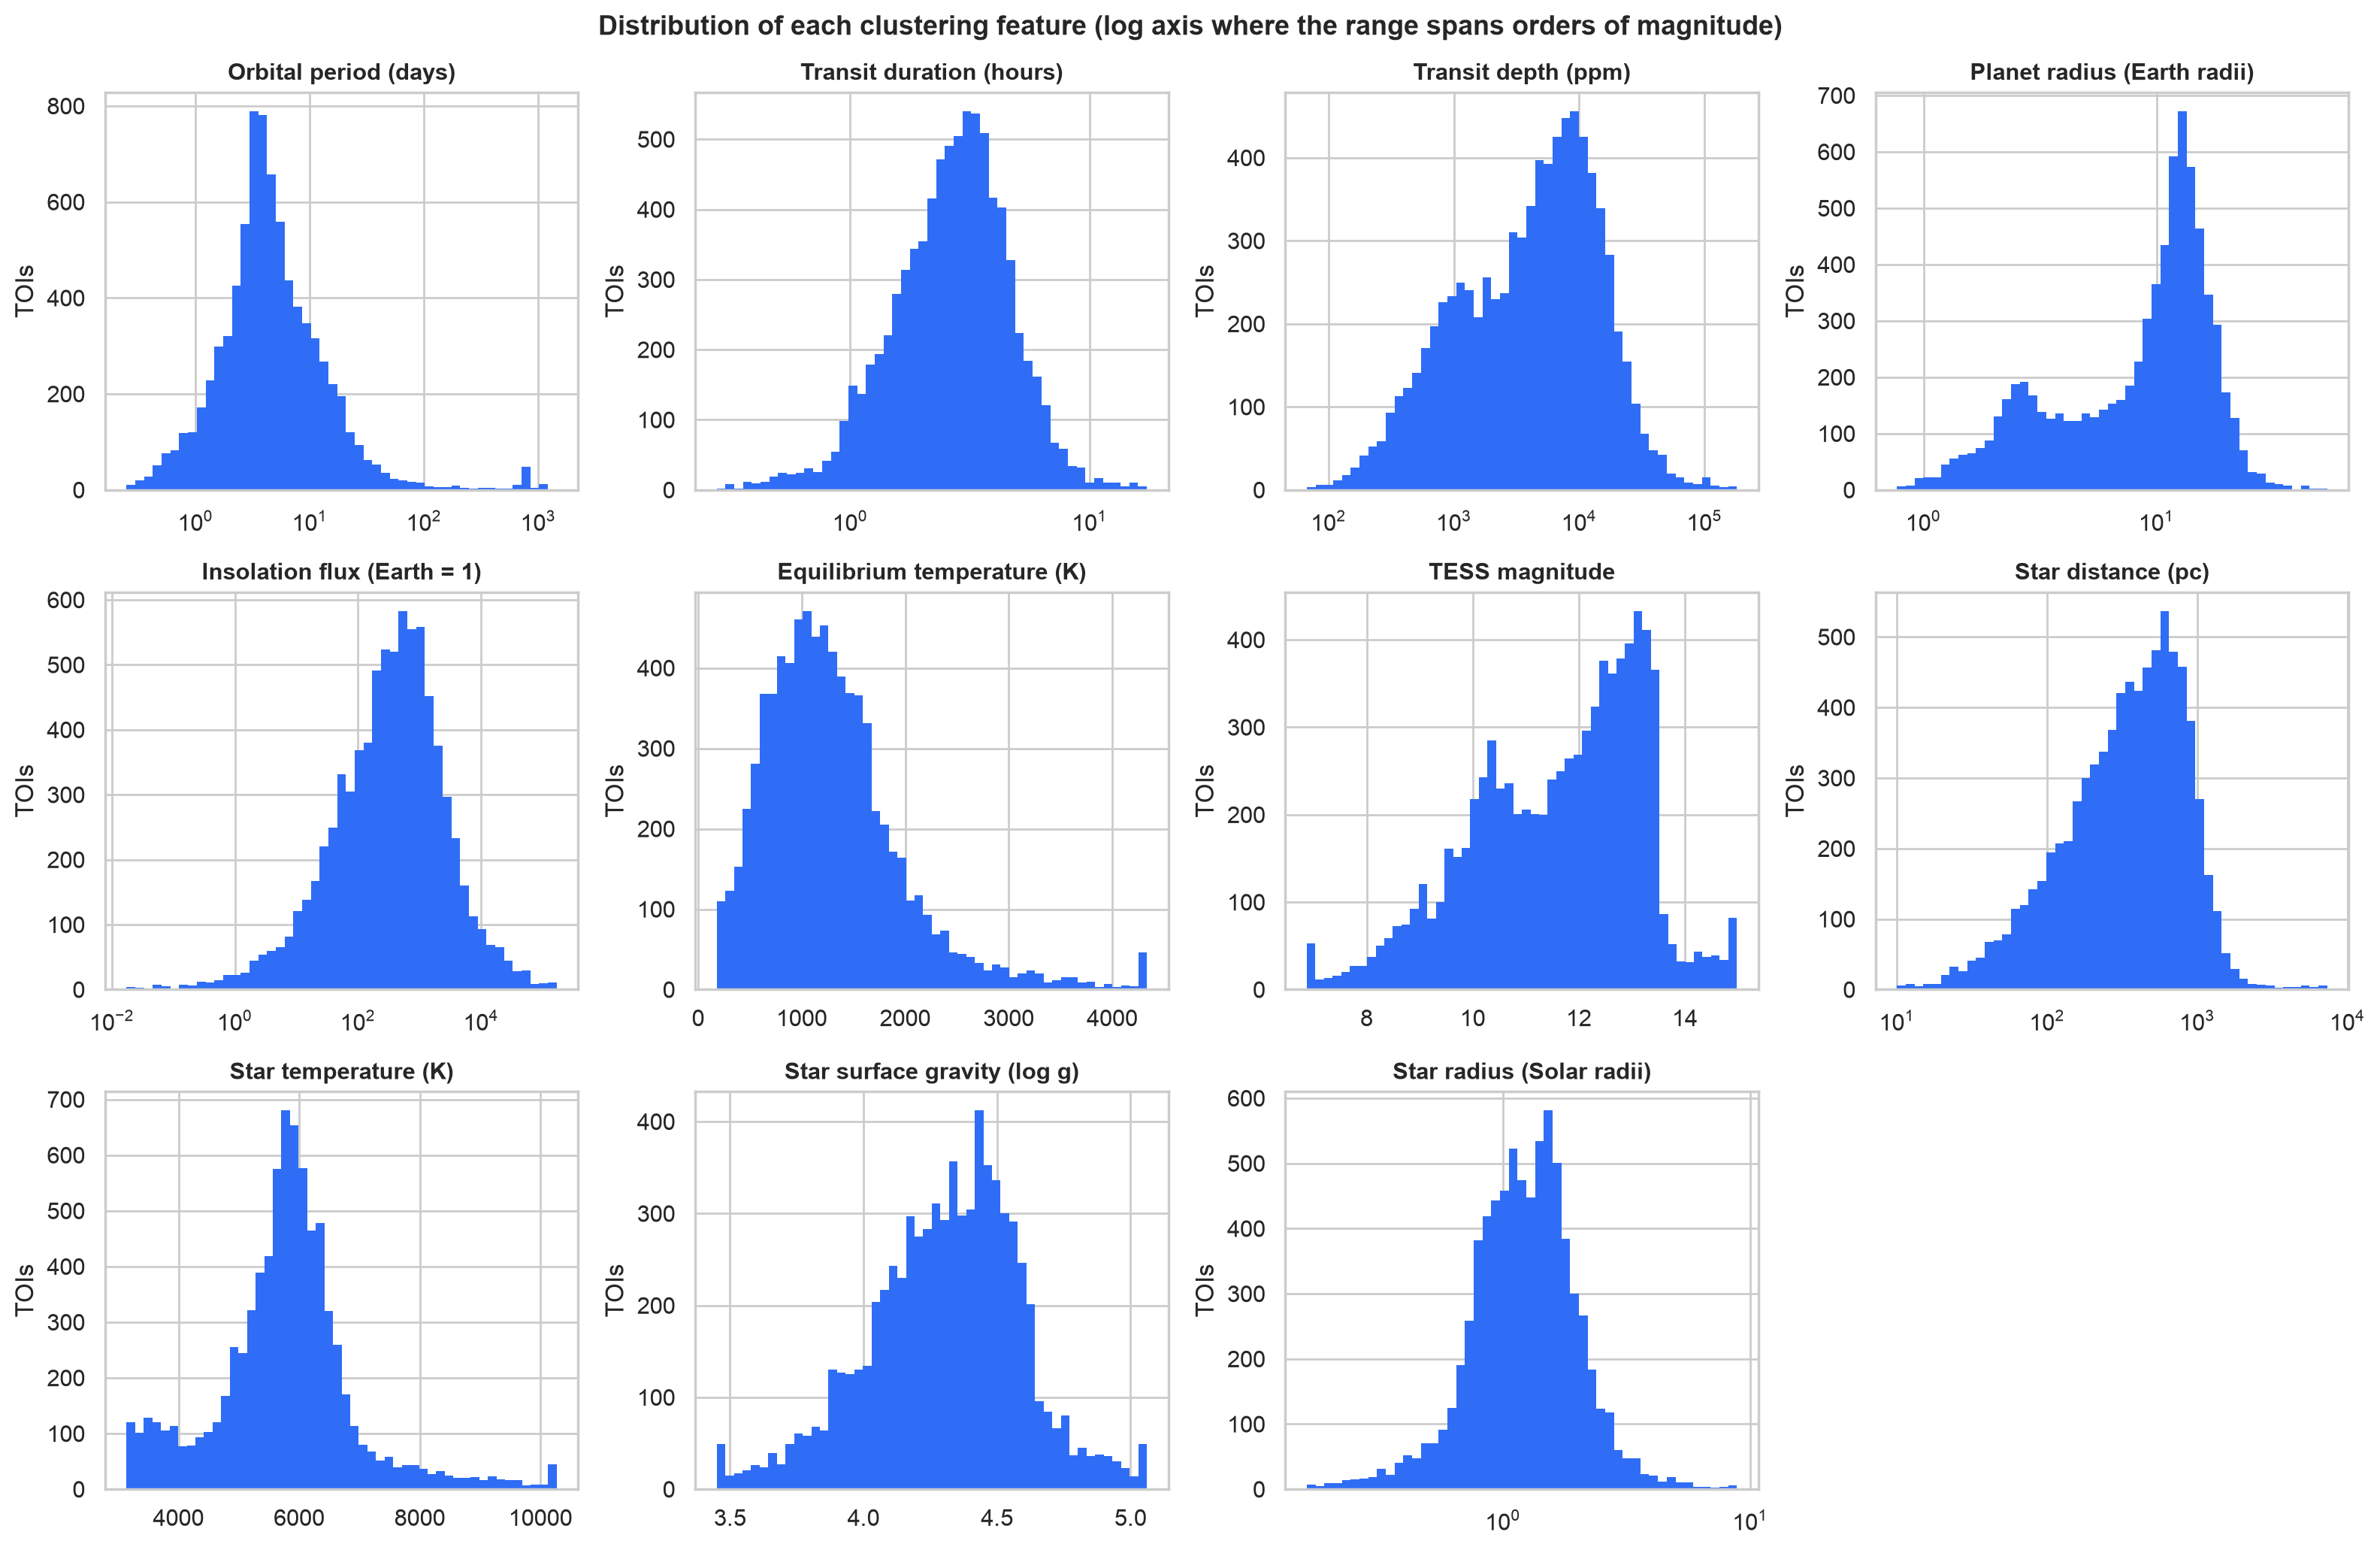

,count,min,50%,max,skew
pl_orbper,8040.0,0.15,4.15,1837.89,10.72
pl_trandurh,8147.0,0.10,2.75,30.02,2.80
pl_trandep,8151.0,24.58,4742.00,767910.31,19.89
pl_rade,7631.0,0.55,10.49,297.11,13.44
pl_insol,7967.0,0.00,378.49,280833.00,13.53
pl_eqt,7837.0,37.00,1194.99,6413.00,1.66
st_tmag,8151.0,4.63,11.88,18.81,-0.51
st_dist,7928.0,6.53,370.69,14728.30,8.76
st_teff,7976.0,2808.00,5799.35,50000.00,9.23
st_logg,7249.0,0.10,4.33,5.96,-0.94


In [3]:
#the eleven measurements used for clustering, with readable names for the plots
FEATURES = {
    'pl_orbper': 'Orbital period (days)',
    'pl_trandurh': 'Transit duration (hours)',
    'pl_trandep': 'Transit depth (ppm)',
    'pl_rade': 'Planet radius (Earth radii)',
    'pl_insol': 'Insolation flux (Earth = 1)',
    'pl_eqt': 'Equilibrium temperature (K)',
    'st_tmag': 'TESS magnitude',
    'st_dist': 'Star distance (pc)',
    'st_teff': 'Star temperature (K)',
    'st_logg': 'Star surface gravity (log g)',
    'st_rad': 'Star radius (Solar radii)',
}
#these span several orders of magnitude, so they are shown and later modelled on a log scale
LOG_FEATURES = ['pl_orbper', 'pl_trandurh', 'pl_trandep', 'pl_rade', 'pl_insol', 'st_dist', 'st_rad']

os.makedirs('figures/Clustering EDA', exist_ok=True)
fig, axes = plt.subplots(3, 4, figsize=(16, 10.5), dpi=200)
for ax, (col, name) in zip(axes.flat, FEATURES.items()):
    s = df[col].dropna()
    if col in LOG_FEATURES:
        s = s[s > 0]
        bins = np.logspace(np.log10(s.quantile(0.001)), np.log10(s.quantile(0.999)), 50)
        ax.hist(s, bins=bins, color='#2f6df6', edgecolor='none')
        ax.set_xscale('log')
    else:
        lo, hi = s.quantile([0.005, 0.995])
        ax.hist(s.clip(lo, hi), bins=50, color='#2f6df6', edgecolor='none')
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.set_ylabel('TOIs')
axes.flat[-1].axis('off')
fig.suptitle('Distribution of each clustering feature (log axis where the range spans orders of magnitude)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Clustering EDA/distributions.png', dpi=300, bbox_inches='tight')
plt.show()

summary = df[list(FEATURES)].describe(percentiles=[0.5]).T[['count', 'min', '50%', 'max']]
summary['skew'] = df[list(FEATURES)].skew()
summary.round(2)

**Observation (A2a):** Seven of the measurements span three to six orders of magnitude (period 0.15 to 1,838 days, depth 25 to 768,000 ppm, star radius 0.1 to 102 solar radii) with skew between 3 and 41, so they are plotted, and later modelled, on a log scale, where they look roughly bell-shaped. Planet radius is the one clearly two-humped feature: a small-planet bump around 2 to 3 Earth radii and a much larger one around 10 to 15 Earth radii, Jupiter-sized objects, which is also where eclipsing binaries hide. Equilibrium temperature peaks near 1,000 to 1,500 K and period near 3 to 5 days, because TESS finds hot, short-period objects most easily. Host stars are mostly Sun-like (about 5,800 K, log g 4.0 to 4.7, one solar radius) with a cool-dwarf tail at 3,000 to 4,000 K. The small spike of periods near 700 to 1,000 days is a batch of single-transit TOIs carrying a placeholder period; the 1st/99th percentile clipping in Section B keeps it from forming a cluster of its own.

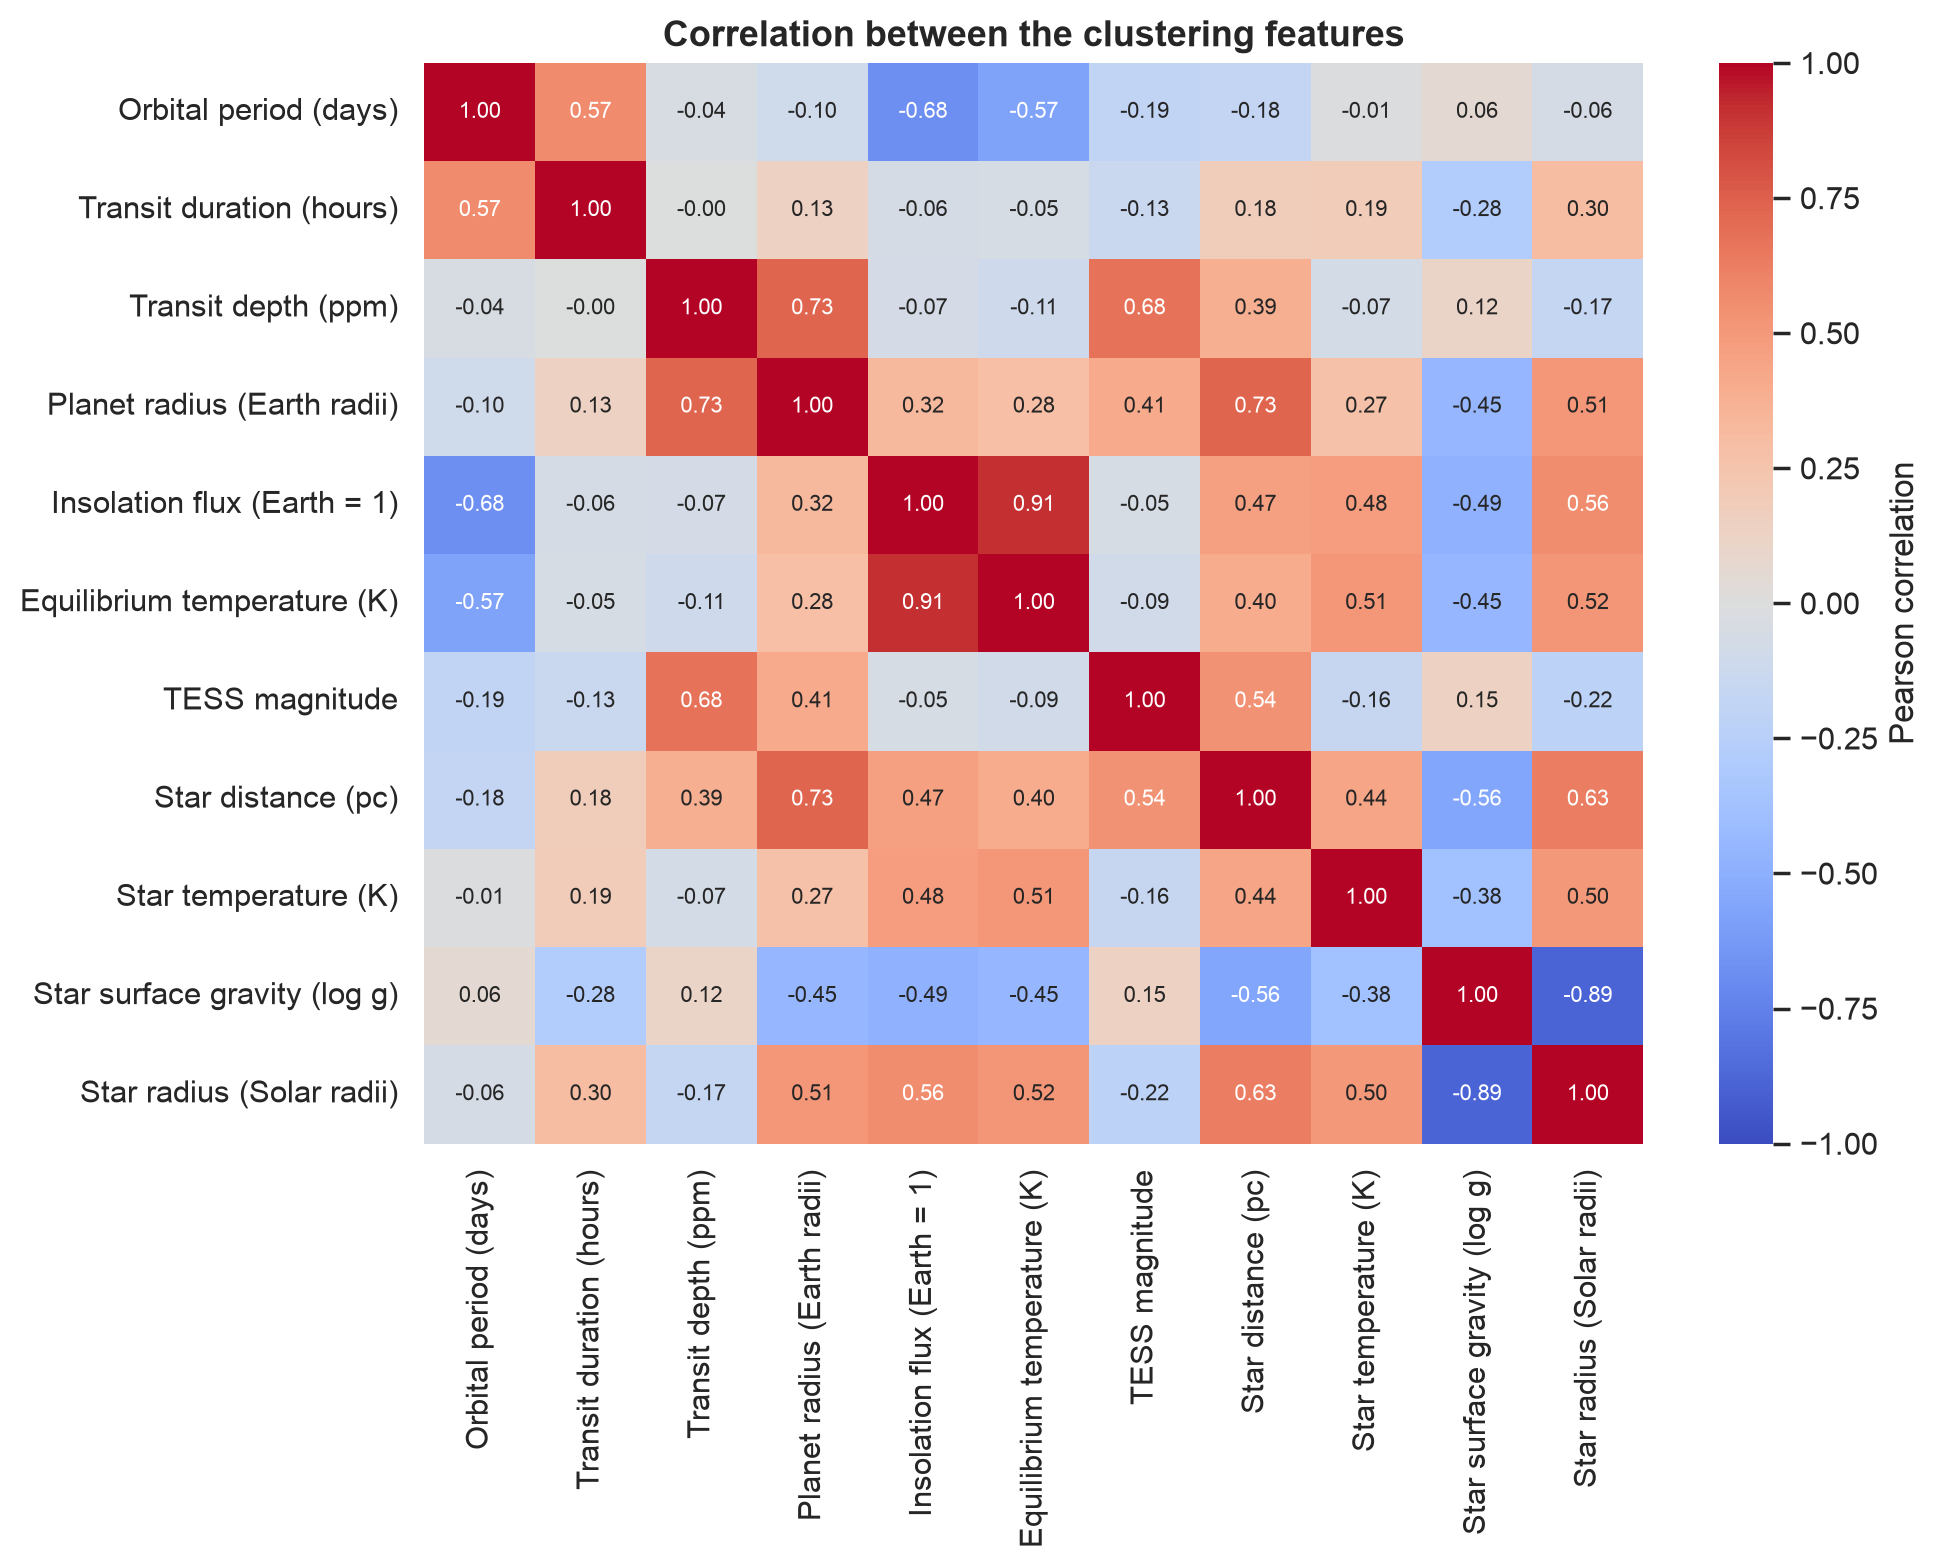

In [4]:
#correlation between the features, on the log scale where one is used, so a few extreme values do not dominate
eda = df[list(FEATURES)].copy()
for col in LOG_FEATURES:
    eda[col] = np.log10(eda[col].where(eda[col] > 0))
corr = eda.corr()

fig, ax = plt.subplots(figsize=(10, 8), dpi=200)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            xticklabels=list(FEATURES.values()), yticklabels=list(FEATURES.values()),
            annot_kws={'size': 8}, cbar_kws={'label': 'Pearson correlation'}, ax=ax)
ax.set_title('Correlation between the clustering features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Clustering EDA/correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation (A2b):** The features relate the way the physics says they should. Insolation and equilibrium temperature are nearly the same quantity (0.91). Star radius and surface gravity are opposites (-0.89): bigger stars have weaker surface gravity. Transit depth tracks planet radius (0.73) because depth scales with the planet-to-star size ratio, and longer periods mean cooler planets (-0.68 with insolation, -0.57 with temperature). Two correlations are selection effects rather than physics: planet radius rises with star distance (0.73) and depth rises with TESS magnitude (0.68), because on faint, far-away stars only big, deep transits can be detected. This redundancy is why two principal components later capture 63% of the variance.

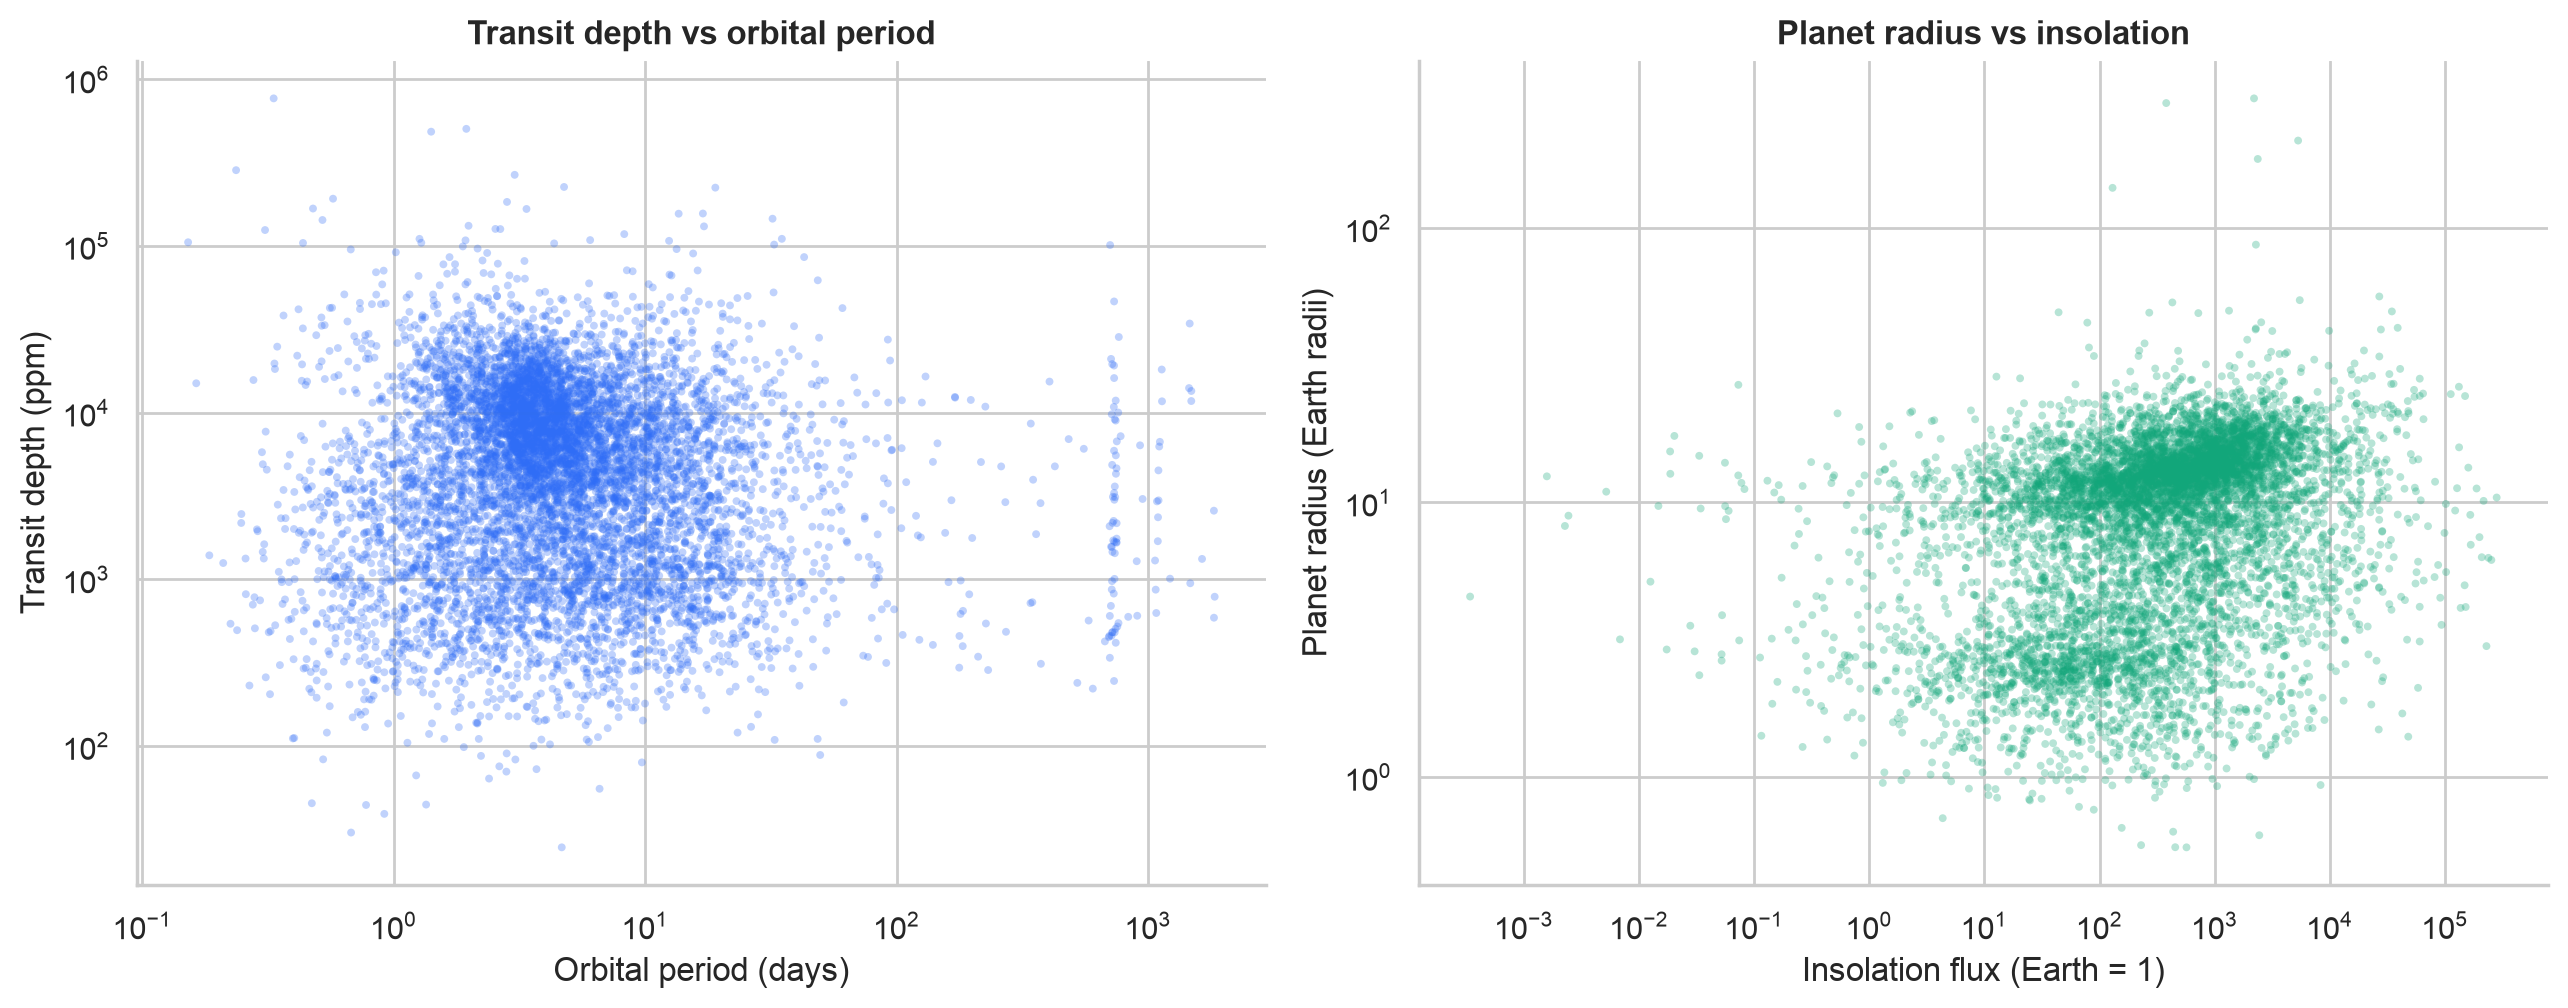

In [5]:
#two feature pairs that physics says should relate: how the signal looks, and how hot the planet is
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), dpi=200)
axes[0].scatter(df['pl_orbper'], df['pl_trandep'], s=8, alpha=0.3, color='#2f6df6', edgecolor='none')
axes[0].set(xscale='log', yscale='log', xlabel='Orbital period (days)', ylabel='Transit depth (ppm)')
axes[0].set_title('Transit depth vs orbital period', fontsize=12, fontweight='bold')
axes[1].scatter(df['pl_insol'], df['pl_rade'], s=8, alpha=0.3, color='#12a67a', edgecolor='none')
axes[1].set(xscale='log', yscale='log', xlabel='Insolation flux (Earth = 1)', ylabel='Planet radius (Earth radii)')
axes[1].set_title('Planet radius vs insolation', fontsize=12, fontweight='bold')
for ax in axes:
    sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('figures/Clustering EDA/feature_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation (A2c):** Depth against period is one dense cloud at 2 to 10 days and 1,000 to 30,000 ppm with no single trend; the vertical stripe near 700 days is the single-transit placeholder batch seen in the histograms. Radius against insolation shows the two bands from the radius histogram, small planets near 2 to 3 Earth radii and giants near 10 to 15, both spread across insolation from 10 to 10,000 times Earth's. That small-versus-giant split is the clearest natural structure in the data, so it is the first thing a clustering algorithm should find.

## Section B - Preprocessing

Clustering has no target and no held-out test set, so there is no train/test split. The scaler is fitted on all rows, which is not leakage here because nothing is being predicted. The disposition column is set aside and only comes back in the interpretation step.

Steps, in order:

1. keep the eleven physical features, drop identifiers, coordinates, dates and error columns
2. log10 the seven heavy-tailed features (period, duration, depth, planet radius, insolation, distance, star radius); K-Means works on euclidean distance, and without the log a handful of giant values would decide every cluster
3. clip every feature at its 1st and 99th percentile so the few remaining extreme points cannot pull a centroid on their own
4. fill the missing values with the column median
5. standardise with `StandardScaler` so every feature has the same weight in the distance

In [6]:
#labels aside, features in
labels = df['tfopwg_disp'].copy()
X_raw = df[list(FEATURES)].copy()

X_prep = X_raw.copy()
for col in LOG_FEATURES:
    X_prep[col] = np.log10(X_prep[col].where(X_prep[col] > 0))  #non-positive values become missing and are imputed below
for col in X_prep.columns:
    lo, hi = X_prep[col].quantile([0.01, 0.99])
    X_prep[col] = X_prep[col].clip(lo, hi)

imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X_prep), columns=X_prep.columns, index=X_prep.index)
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X_imputed), columns=X_prep.columns, index=X_prep.index)

print(f"Clustering matrix: {X.shape[0]:,} rows x {X.shape[1]} features, missing values: {int(X.isna().sum().sum())}")
check = pd.DataFrame({'skew before': X_raw.skew().round(2), 'skew after log + clip': X_imputed.skew().round(2),
                      'mean after scaling': X.mean().round(2), 'std after scaling': X.std().round(2)})
check

Clustering matrix: 8,151 rows x 11 features, missing values: 0


,skew before,skew after log + clip,mean after scaling,std after scaling
pl_orbper,10.72,1.16,0.0,1.0
pl_trandurh,2.80,-0.37,-0.0,1.0
pl_trandep,19.89,-0.37,0.0,1.0
pl_rade,13.44,-0.86,-0.0,1.0
pl_insol,13.53,-0.44,0.0,1.0
pl_eqt,1.66,1.23,0.0,1.0
st_tmag,-0.51,-0.47,0.0,1.0
st_dist,8.76,-0.66,-0.0,1.0
st_teff,9.23,0.41,0.0,1.0
st_logg,-0.94,-0.33,0.0,1.0


## Section C - K-Means Clustering

### C1. What is K-Means?

K-Means splits the rows into `k` groups by placing `k` centre points (centroids) and moving them until every row sits with its nearest centre.

- **How it learns:** start with `k` centroids (k-means++ spreads the starting points out), assign each row to its nearest centroid, move each centroid to the mean of its rows, repeat until nothing changes. `n_init=10` runs that from ten different starts and keeps the best.
- **Inertia:** the sum of squared distances from every row to its centroid. Lower is tighter, and it always falls as `k` grows, which is why the elbow matters.
- **Elbow curve:** inertia against `k`. The bend is where adding another cluster stops buying much.
- **Silhouette:** for each row, how close it is to its own cluster compared with the nearest other cluster, from -1 to 1. Averaged over all rows it scores a whole clustering, so it is a second opinion on `k`.
- **Why scaling:** distance mixes every feature at once, so without Section B a star's distance in parsecs would outweigh everything else.
- **Limits:** it assumes roughly round clusters of similar size, needs `k` chosen by hand, and is pulled by outliers, which is why the features were logged and clipped.

### C2. Choosing k

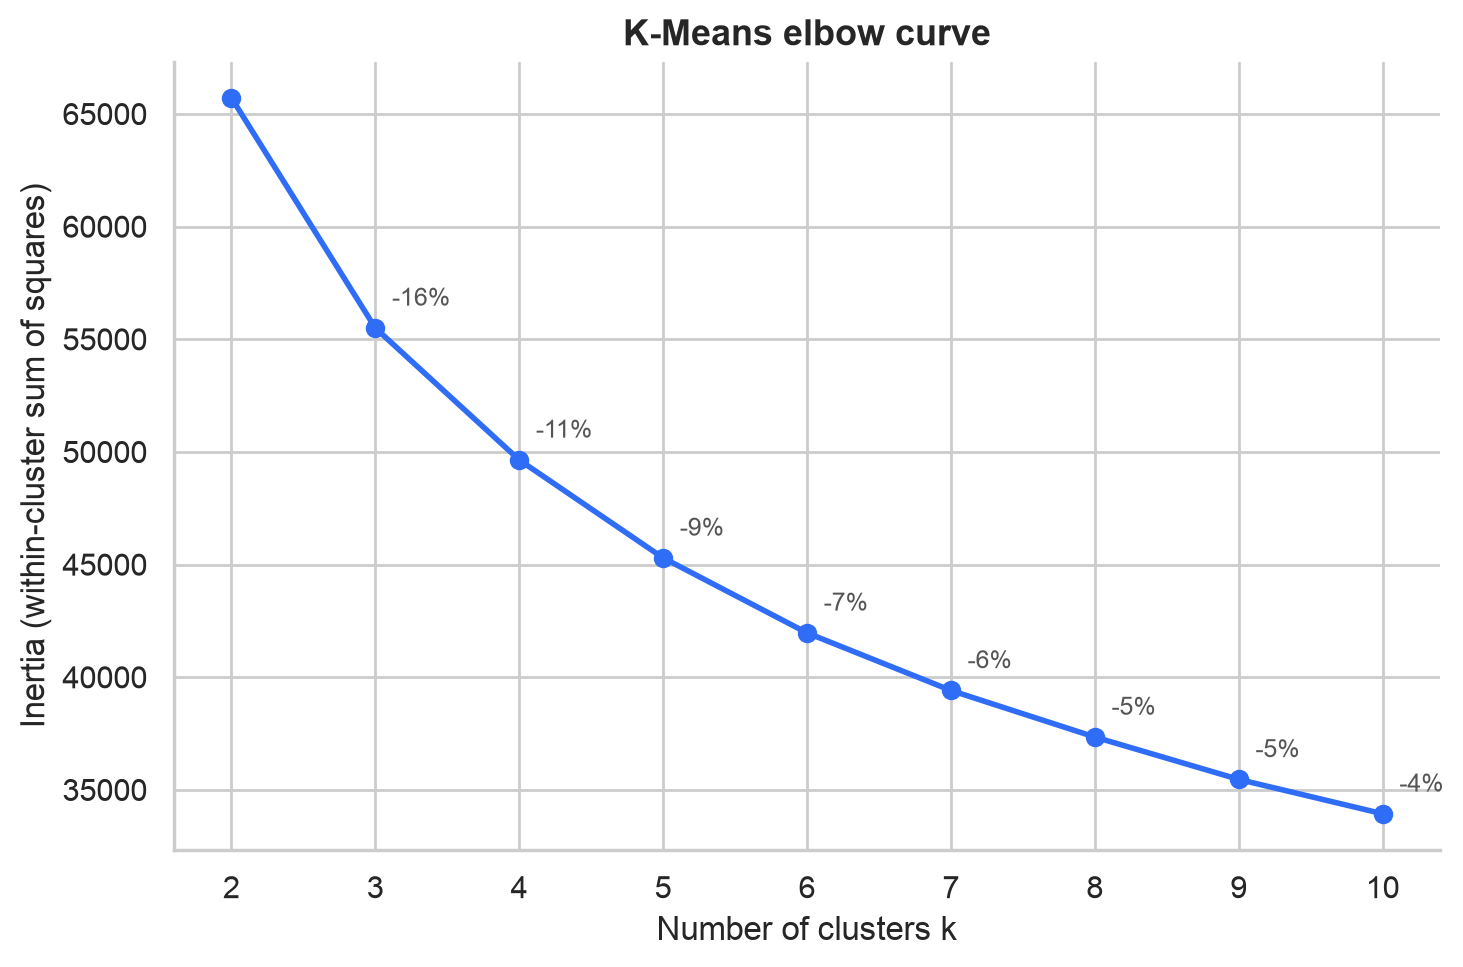

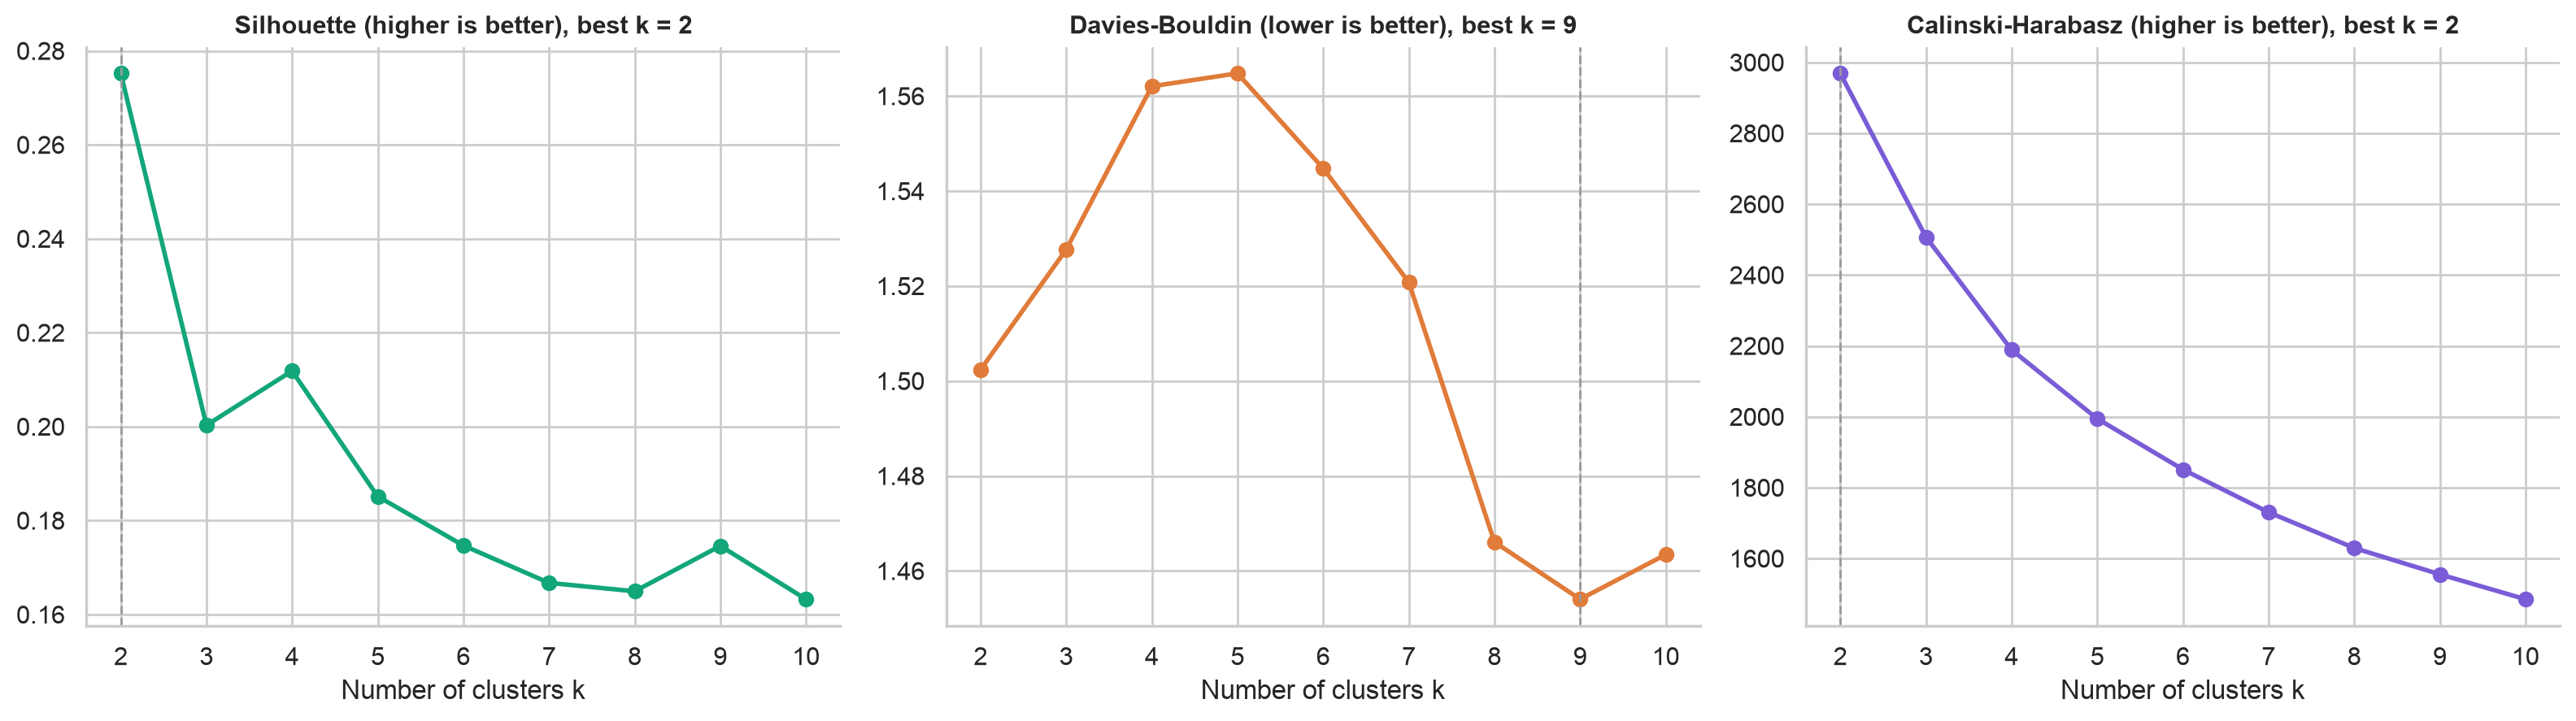

Best k by silhouette: 2 | by Davies-Bouldin: 9 | by Calinski-Harabasz: 2


,k,inertia,inertia drop (%),silhouette,davies_bouldin,calinski_harabasz
0,2,65717.4262,NaN,0.2752,1.5024,2969.0180
1,3,55503.0477,15.5,0.2003,1.5277,2507.2420
2,4,49644.9323,10.6,0.2119,1.5621,2188.9515
3,5,45295.6471,8.8,0.1851,1.5648,1994.6752
4,6,41967.5683,7.3,0.1747,1.5448,1851.2572
5,7,39411.7037,6.1,0.1667,1.5208,1730.5792
6,8,37344.2551,5.2,0.1649,1.4661,1629.6852
7,9,35463.4058,5.0,0.1746,1.4540,1555.3952
8,10,33939.2931,4.3,0.1633,1.4634,1485.1040


In [7]:
#sweep k: inertia for the elbow, plus the three internal metrics so the choice of k does not rest on one number
ks = range(2, 11)
sweep = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    sweep.append({'k': k, 'inertia': km.inertia_,
                  'silhouette': silhouette_score(X, km.labels_),
                  'davies_bouldin': davies_bouldin_score(X, km.labels_),
                  'calinski_harabasz': calinski_harabasz_score(X, km.labels_)})
sweep = pd.DataFrame(sweep)
sweep.insert(2, 'inertia drop (%)', (-sweep['inertia'].pct_change() * 100).round(1))

os.makedirs('figures/K-Means', exist_ok=True)
fig, ax = plt.subplots(figsize=(7.5, 5), dpi=200)
ax.plot(sweep['k'], sweep['inertia'], marker='o', color='#2f6df6', lw=2)
for k, drop in zip(sweep['k'][1:], sweep['inertia drop (%)'][1:]):
    ax.annotate(f'-{drop:.0f}%', (k, sweep.loc[sweep['k'] == k, 'inertia'].iloc[0]), textcoords='offset points', xytext=(6, 8), fontsize=9, color='#555')
ax.set(xlabel='Number of clusters k', ylabel='Inertia (within-cluster sum of squares)', xticks=list(ks))
ax.set_title('K-Means elbow curve', fontsize=13, fontweight='bold')
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('figures/K-Means/elbow_curve.png', dpi=300, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), dpi=200)
for ax, (metric, title, color, best) in zip(axes, [
        ('silhouette', 'Silhouette (higher is better)', '#12a67a', 'max'),
        ('davies_bouldin', 'Davies-Bouldin (lower is better)', '#e07b39', 'min'),
        ('calinski_harabasz', 'Calinski-Harabasz (higher is better)', '#7a5cd6', 'max')]):
    ax.plot(sweep['k'], sweep[metric], marker='o', color=color, lw=2)
    kbest = int(sweep.loc[getattr(sweep[metric], 'idx' + best)(), 'k'])
    ax.axvline(kbest, color='#999', ls='--', lw=1)
    ax.set(xlabel='Number of clusters k', xticks=list(ks))
    ax.set_title(f'{title}, best k = {kbest}', fontsize=11, fontweight='bold')
    sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('figures/K-Means/k_selection_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

print("Best k by silhouette:", int(sweep.loc[sweep['silhouette'].idxmax(), 'k']),
      "| by Davies-Bouldin:", int(sweep.loc[sweep['davies_bouldin'].idxmin(), 'k']),
      "| by Calinski-Harabasz:", int(sweep.loc[sweep['calinski_harabasz'].idxmax(), 'k']))
sweep.round(4)

**Observation (C2):** Silhouette and Calinski-Harabasz both favor `k = 2`: silhouette is 0.275 and Calinski-Harabasz is 2,969 there, and both fall as `k` grows. Davies-Bouldin is fairly flat, around 1.45 to 1.56, and has its minimum at `k = 9`. The elbow is gradual: inertia falls 15.5% from 2 to 3 clusters, 10.6% from 3 to 4, then less than 9% per added group. A smaller silhouette bump at `k = 4` (0.212) motivates the finer view in C4. The reported model uses `k = 2`.

### C3. Final model

In [8]:
K_CHOSEN = 2
k_final = K_CHOSEN or int(sweep.loc[sweep['silhouette'].idxmax(), 'k'])

kmeans = KMeans(n_clusters=k_final, n_init=10, random_state=RANDOM_STATE).fit(X)
km_labels = pd.Series(kmeans.labels_, index=X.index, name='kmeans_cluster')
print(f"K-Means with k = {k_final}: inertia {kmeans.inertia_:.1f}, converged in {kmeans.n_iter_} iterations")
print("Cluster sizes:", km_labels.value_counts().sort_index().to_dict())

#shared containers: the agglomerative section appends to these so sections e and f compare both algorithms
cluster_results = []
cluster_labels = {}

def score_clustering(name, lab):
    row = {'Algorithm': name, 'Clusters': int(pd.Series(lab).nunique()),
           'Silhouette': silhouette_score(X, lab),
           'Davies-Bouldin': davies_bouldin_score(X, lab),
           'Calinski-Harabasz': calinski_harabasz_score(X, lab)}
    cluster_results[:] = [r for r in cluster_results if r['Algorithm'] != name]
    cluster_results.append(row)
    cluster_labels[name] = pd.Series(lab, index=X.index)
    return row

km_scores = score_clustering('K-Means', km_labels)
pd.DataFrame([km_scores]).round(4)

K-Means with k = 2: inertia 65717.4, converged in 13 iterations
Cluster sizes: {0: 5340, 1: 2811}


,Algorithm,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,2,0.2752,1.5024,2969.018


PC1 explains 40.5% of the variance, PC2 22.5%, together 63.0%


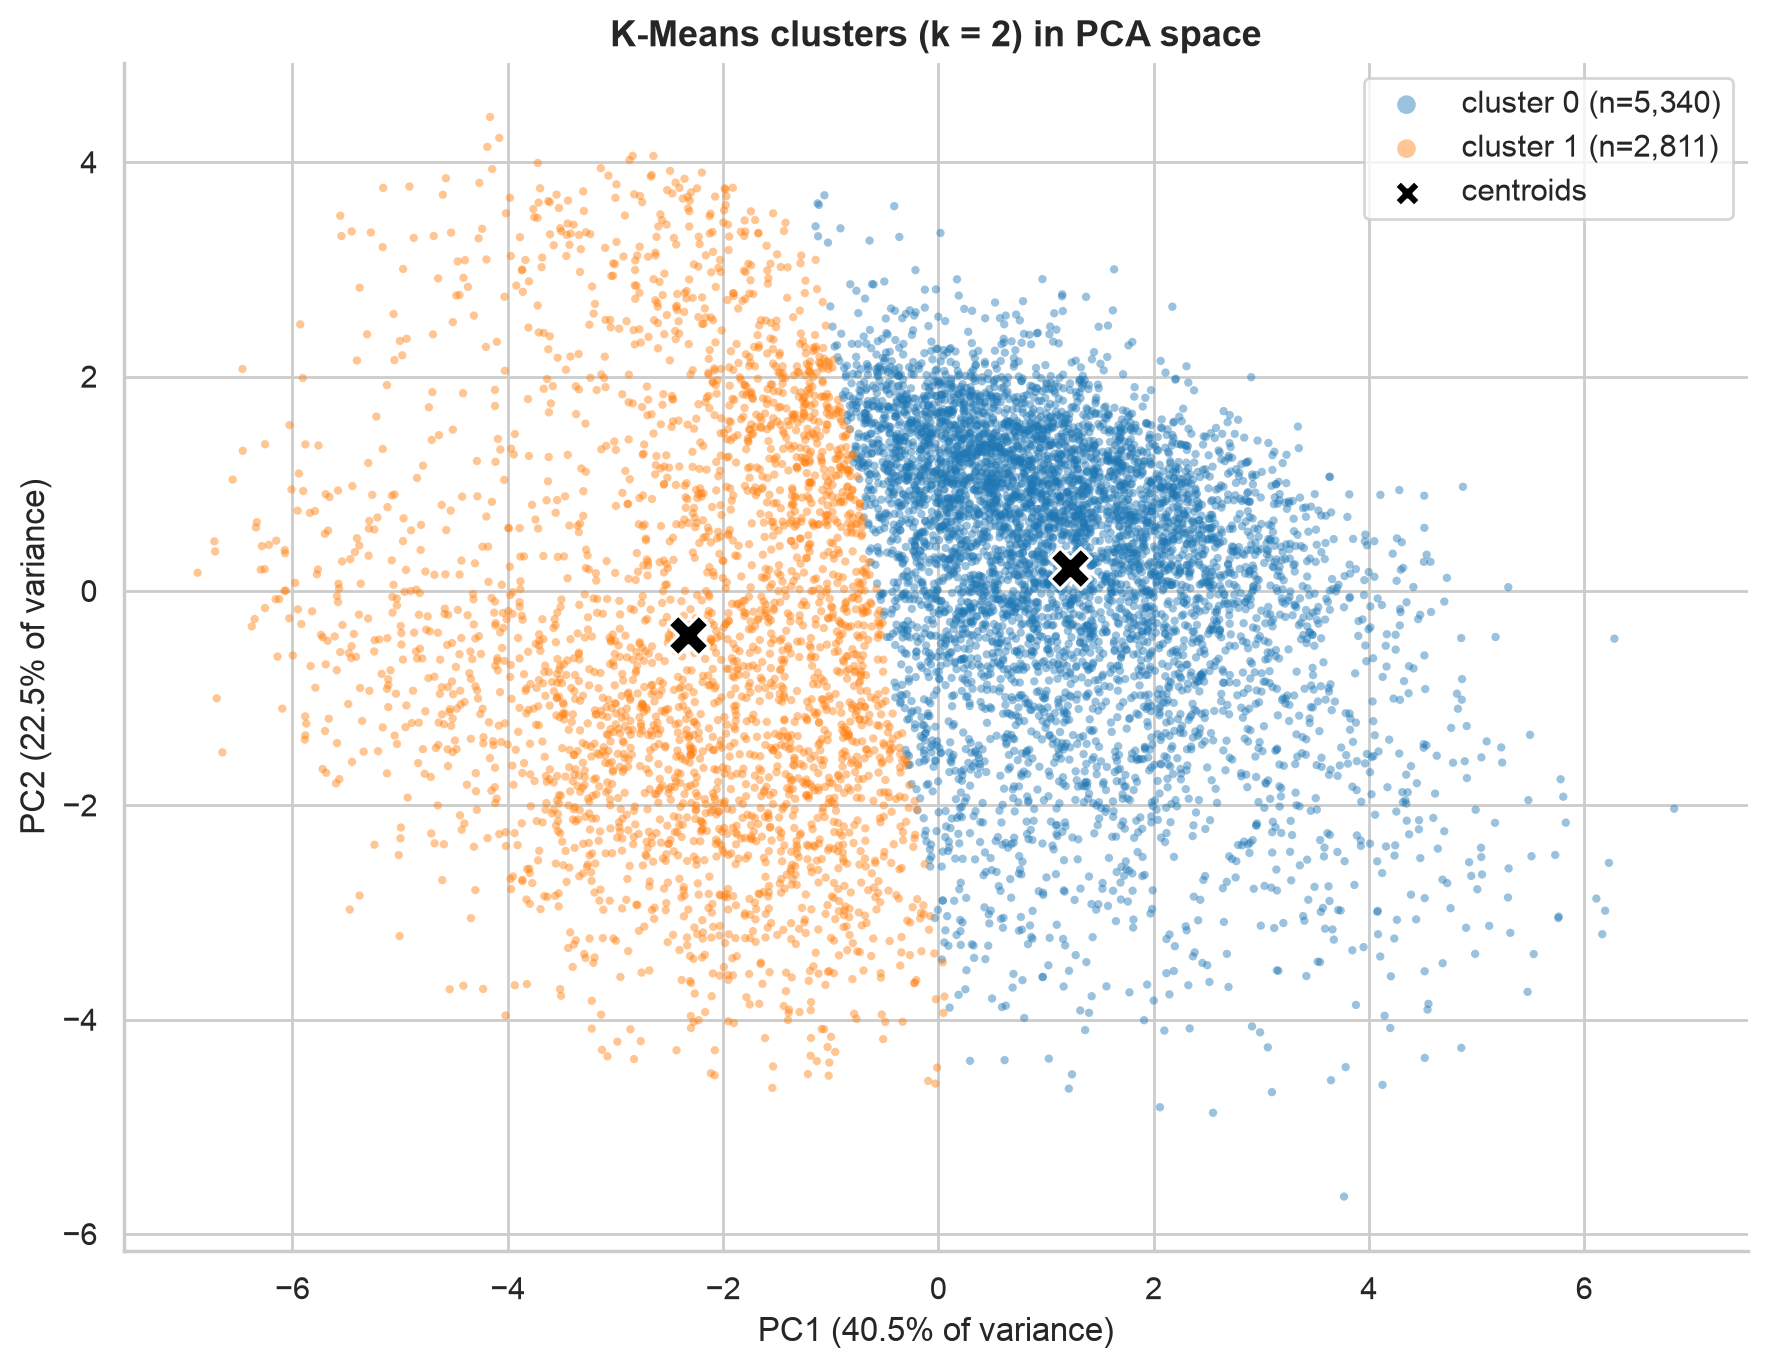

,PC1,PC2
Orbital period (days),-0.17,-0.06
Transit duration (hours),0.08,-0.08
Transit depth (ppm),0.06,0.58
Planet radius (Earth radii),0.31,0.38
Insolation flux (Earth = 1),0.39,-0.11
Equilibrium temperature (K),0.37,-0.14
TESS magnitude,0.03,0.56
Star distance (pc),0.37,0.28
Star temperature (K),0.36,-0.18
Star surface gravity (log g),-0.37,0.14


In [9]:
#pca to two components, fitted on the scaled features, used only to draw the clusters
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
centroids_pca = pca.transform(pd.DataFrame(kmeans.cluster_centers_, columns=X.columns))
ev = pca.explained_variance_ratio_ * 100
print(f"PC1 explains {ev[0]:.1f}% of the variance, PC2 {ev[1]:.1f}%, together {ev.sum():.1f}%")

loadings = pd.DataFrame(pca.components_.T, index=list(FEATURES.values()), columns=['PC1', 'PC2']).round(2)

fig, ax = plt.subplots(figsize=(9, 7), dpi=200)
palette = sns.color_palette('tab10', k_final)
for c in range(k_final):
    m = km_labels == c
    ax.scatter(X_pca[m, 0], X_pca[m, 1], s=9, alpha=0.45, color=palette[c], edgecolor='none', label=f'cluster {c} (n={m.sum():,})')
ax.scatter(centroids_pca[:, 0], centroids_pca[:, 1], s=220, marker='X', color='black', edgecolor='white', linewidth=1.2, label='centroids', zorder=5)
ax.set_xlabel(f'PC1 ({ev[0]:.1f}% of variance)')
ax.set_ylabel(f'PC2 ({ev[1]:.1f}% of variance)')
ax.set_title(f'K-Means clusters (k = {k_final}) in PCA space', fontsize=13, fontweight='bold')
leg = ax.legend(frameon=True)
for handle, size in zip(leg.legend_handles, [45] * k_final + [90]):  #readable point markers, centroid marker kept modest
    handle.set_sizes([size])
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('figures/K-Means/pca_clusters.png', dpi=300, bbox_inches='tight')
plt.show()
loadings

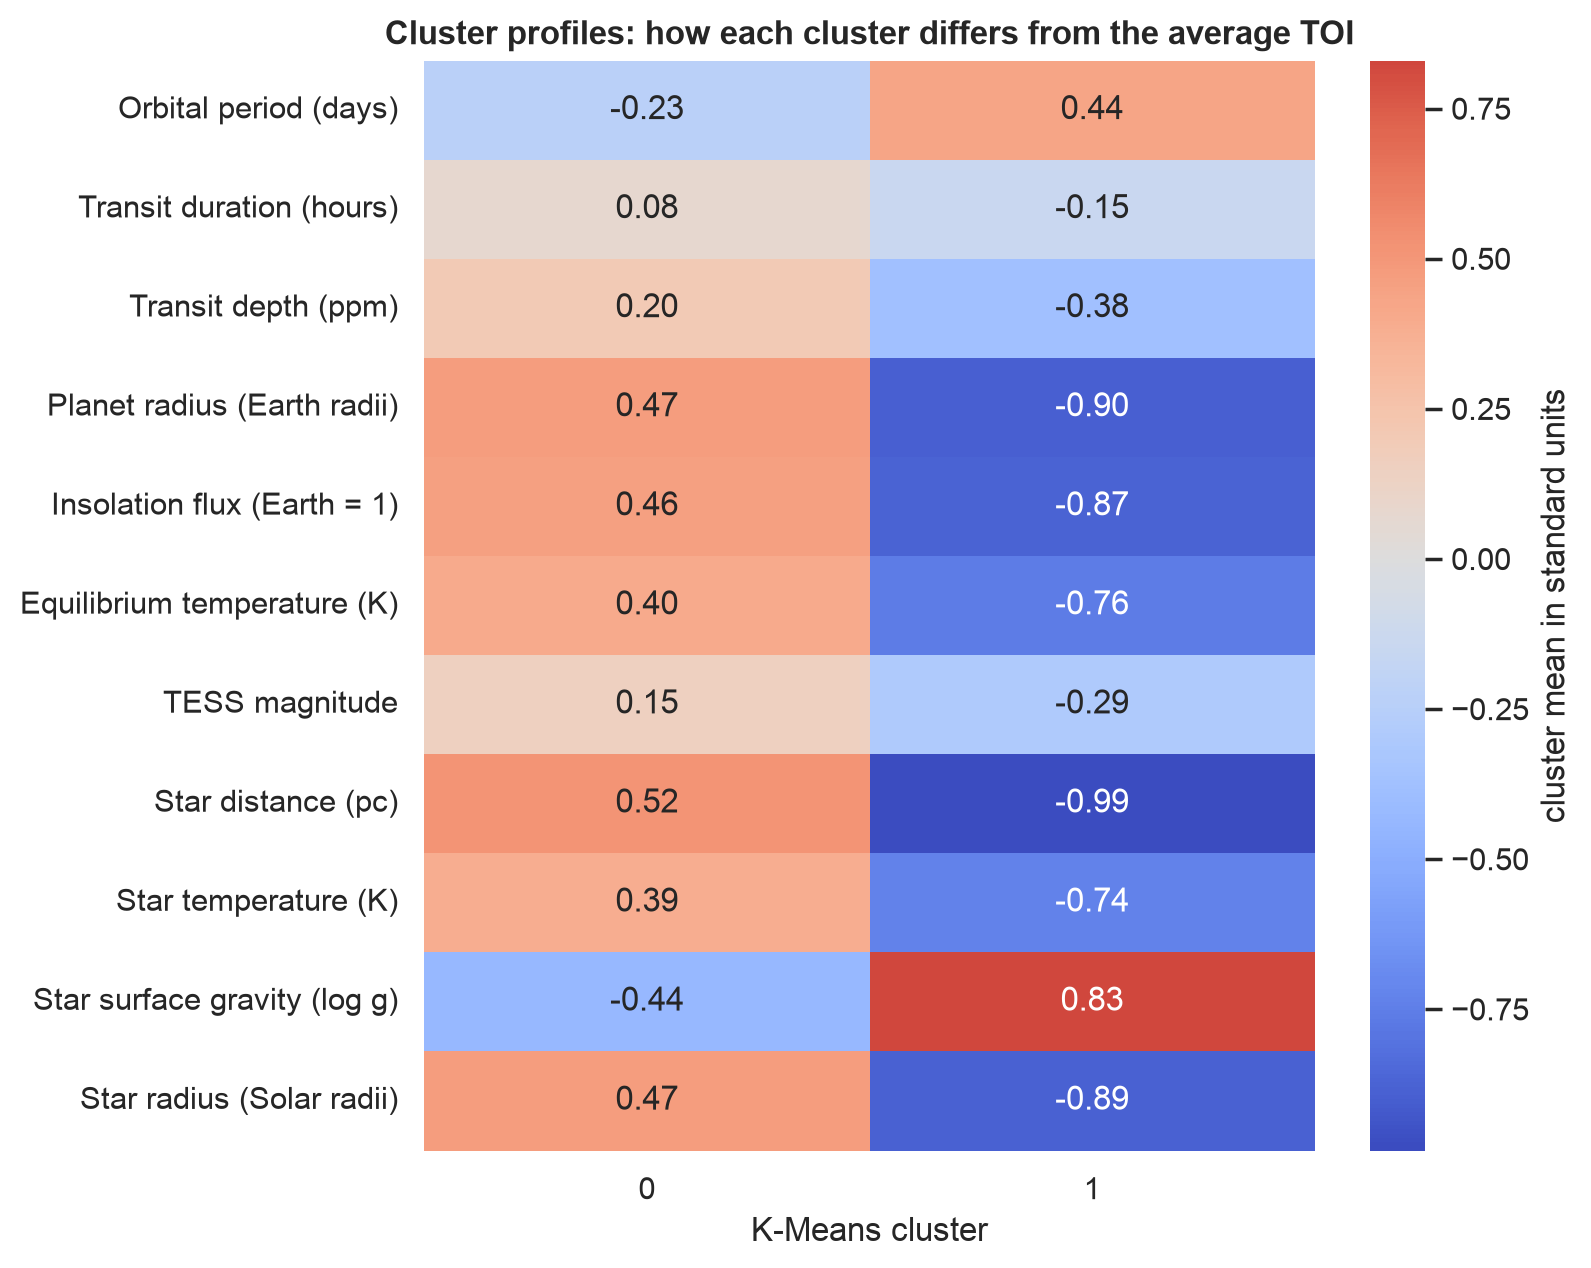

,cluster 0,cluster 1,overall median
Orbital period (days),3.61,7.07,4.15
Transit duration (hours),2.90,2.48,2.75
Transit depth (ppm),6065.41,1707.69,4742.00
Planet radius (Earth radii),12.71,3.45,10.49
Insolation flux (Earth = 1),796.30,56.43,378.49
Equilibrium temperature (K),1441.00,739.82,1194.99
TESS magnitude,12.23,11.05,11.88
Star distance (pc),557.36,137.30,370.69
Star temperature (K),6046.30,5081.00,5799.35
Star surface gravity (log g),4.20,4.53,4.33


In [10]:
#what each cluster looks like in the original units (medians), and which features separate them most
profile = X_raw.assign(cluster=km_labels).groupby('cluster').median().T
profile.index = [FEATURES[c] for c in profile.index]
profile.columns = [f'cluster {c}' for c in profile.columns]
profile['overall median'] = X_raw.median().values

#standardised cluster means show the separation per feature on one colour scale
zmeans = X.assign(cluster=km_labels).groupby('cluster').mean().T
zmeans.index = [FEATURES[c] for c in zmeans.index]
fig, ax = plt.subplots(figsize=(8, 6.5), dpi=200)
sns.heatmap(zmeans, annot=True, fmt='.2f', cmap='coolwarm', center=0, cbar_kws={'label': 'cluster mean in standard units'}, ax=ax)
ax.set_xlabel('K-Means cluster')
ax.set_title('Cluster profiles: how each cluster differs from the average TOI', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/K-Means/cluster_profiles.png', dpi=300, bbox_inches='tight')
plt.show()
profile.round(2)

### C4. Results and interpretation

Only now do the labels come in, to read what the clusters contain. They played no part in the fitting.

Rows per cluster and disposition group:


tfopwg_disp,candidate,not a planet,planet,unknown
kmeans_cluster,,,,
0,3632,1089,617,2
1,1678,326,804,3


Share of each cluster (%):


tfopwg_disp,candidate,not a planet,planet,unknown
kmeans_cluster,,,,
0,68.0,20.4,11.6,0.0
1,59.7,11.6,28.6,0.1


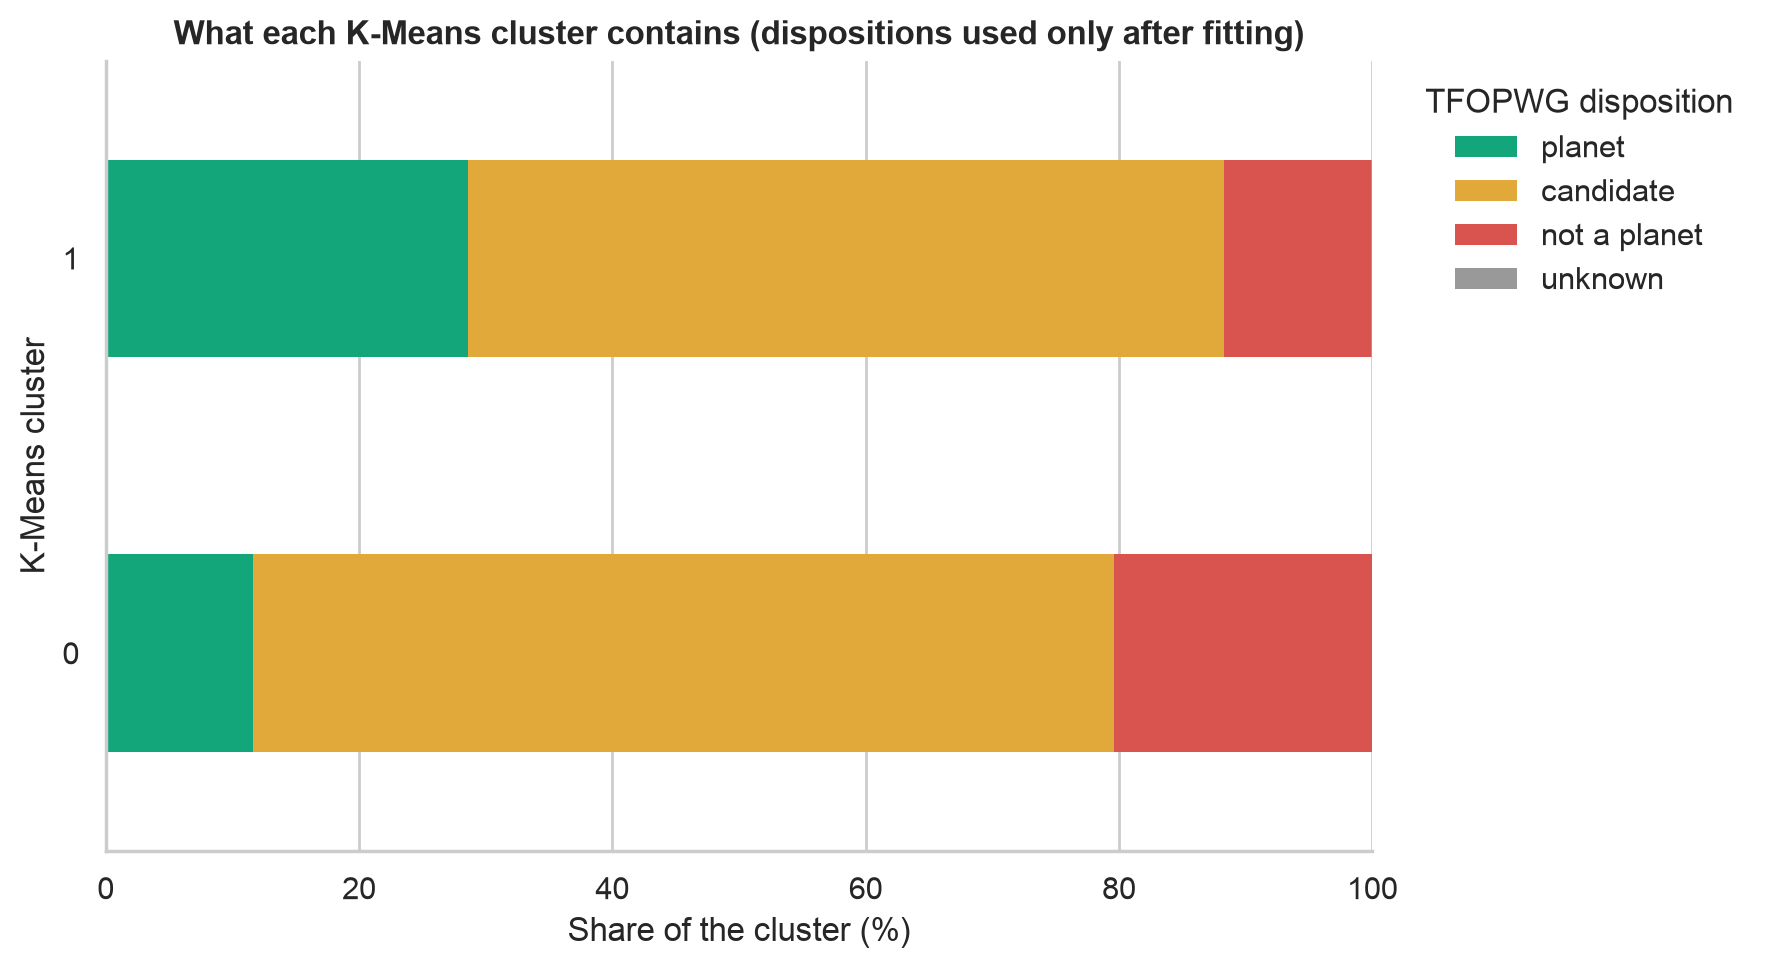

tfopwg_disp,APC,CP,FA,FP,KP,PC,missing
kmeans_cluster,,,,,,,
0,382,198,43,1046,419,3250,2
1,108,617,57,269,187,1570,3


In [11]:
#disposition groups: planets (confirmed + known), candidates (planet + ambiguous), not planets (false positive + false alarm)
group_map = {'CP': 'planet', 'KP': 'planet', 'PC': 'candidate', 'APC': 'candidate', 'FP': 'not a planet', 'FA': 'not a planet'}
disp_group = labels.map(group_map).fillna('unknown')

counts = pd.crosstab(km_labels, disp_group)
share = (pd.crosstab(km_labels, disp_group, normalize='index') * 100).round(1)
print("Rows per cluster and disposition group:")
display(counts)
print("Share of each cluster (%):")
display(share)

fig, ax = plt.subplots(figsize=(9, 5), dpi=200)
order = [c for c in ['planet', 'candidate', 'not a planet', 'unknown'] if c in share.columns]
share[order].plot(kind='barh', stacked=True, ax=ax, color=['#12a67a', '#e0a93a', '#d9534f', '#999999'][:len(order)], edgecolor='none')
ax.set_xlabel('Share of the cluster (%)')
ax.set_ylabel('K-Means cluster')
ax.set_title('What each K-Means cluster contains (dispositions used only after fitting)', fontsize=12, fontweight='bold')
ax.legend(title='TFOPWG disposition', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('figures/K-Means/clusters_vs_disposition.png', dpi=300, bbox_inches='tight')
plt.show()

#fine-grained view for the viva
pd.crosstab(km_labels, labels.fillna('missing'))

k = 4 cluster sizes: {0: 1964, 1: 3609, 2: 1598, 3: 980}


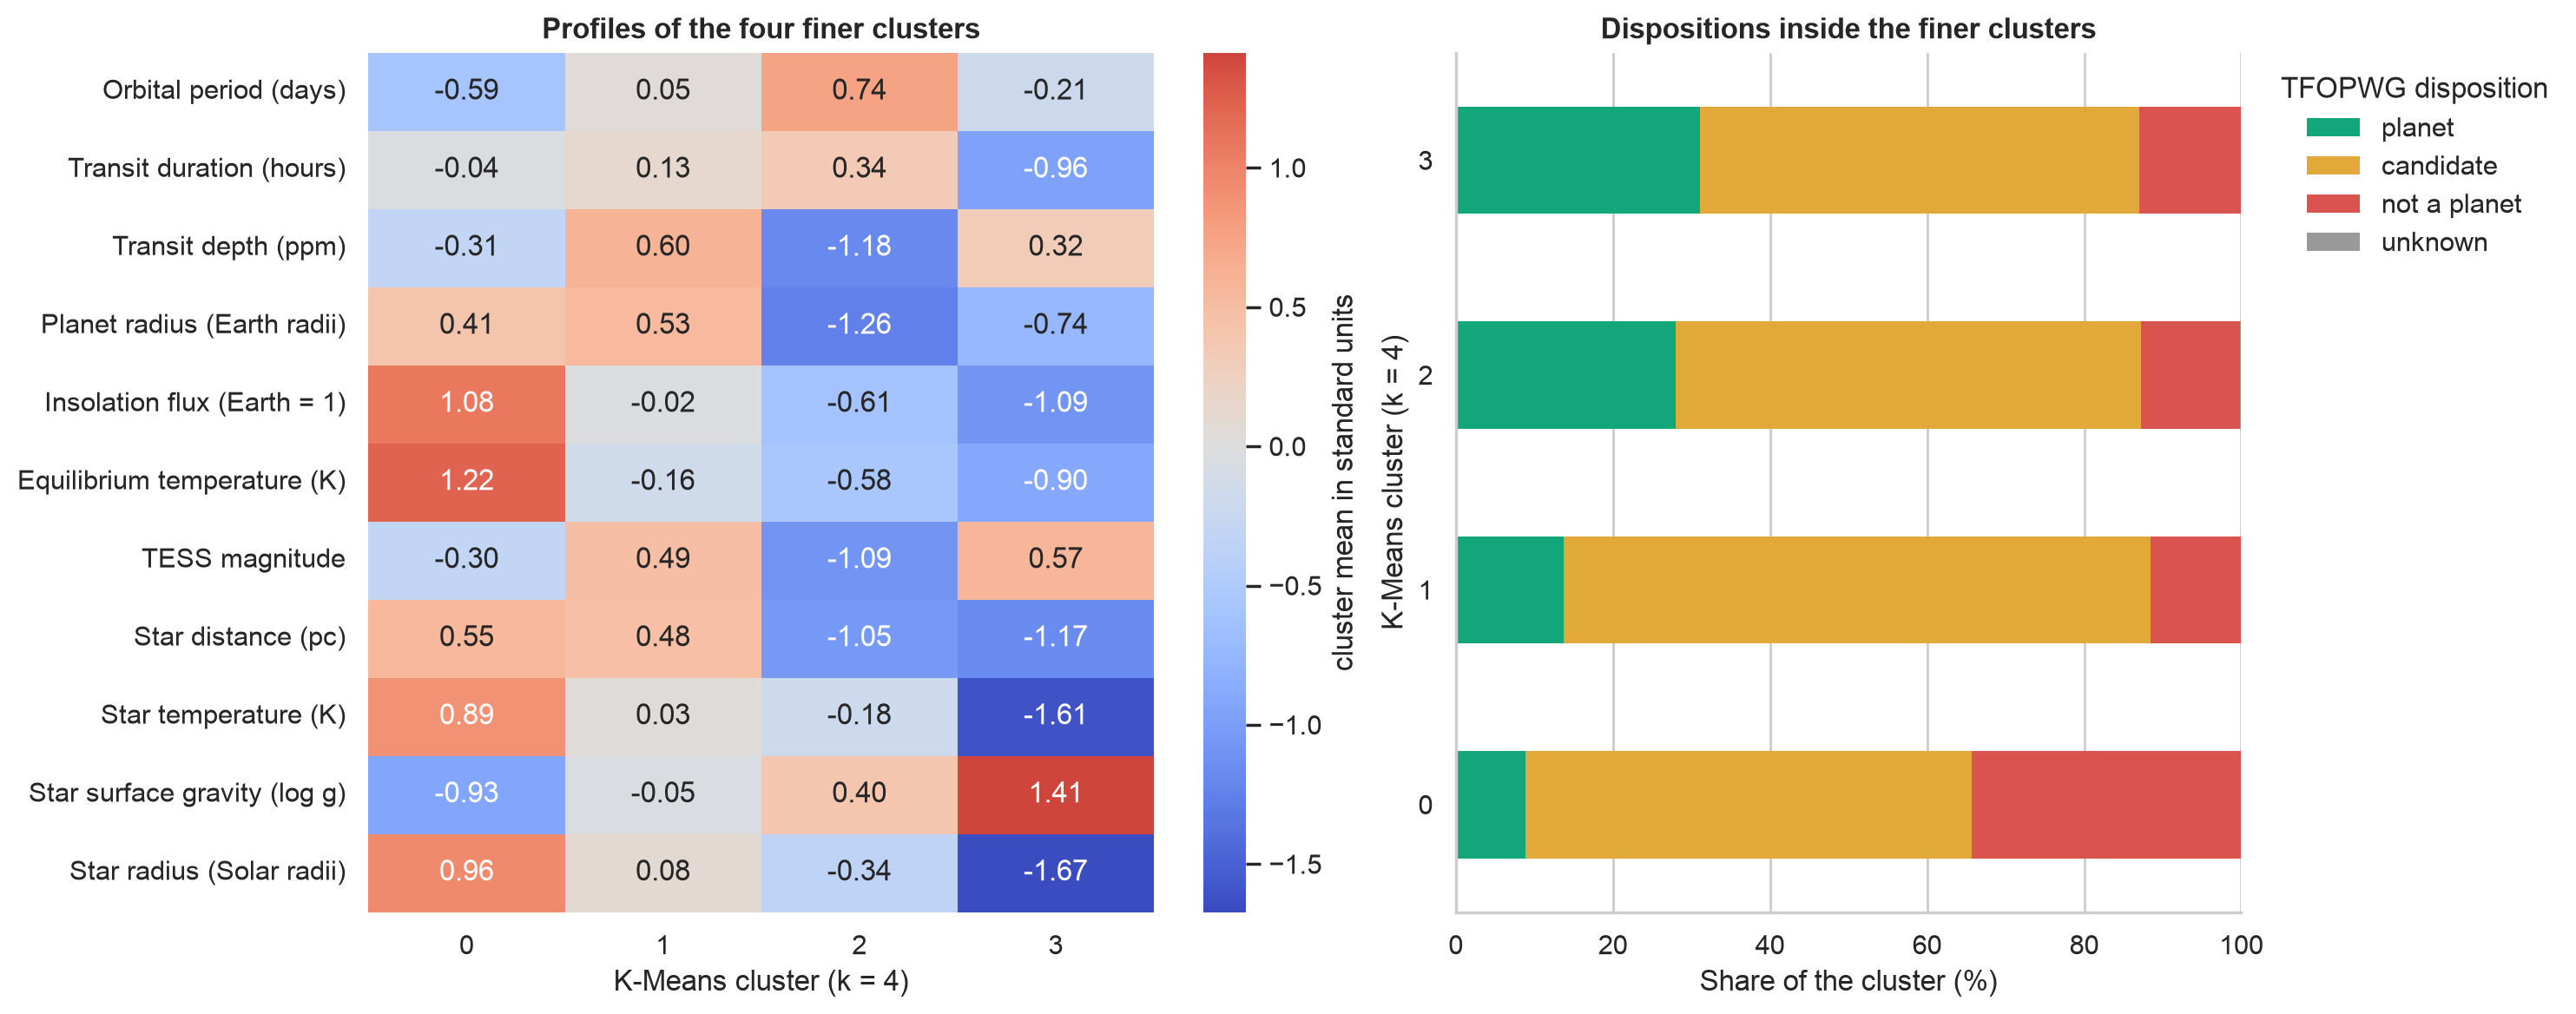

,cluster 0,cluster 1,cluster 2,cluster 3
Orbital period (days),2.62,4.32,9.56,3.57
Transit duration (hours),2.77,2.92,3.21,1.59
Transit depth (ppm),2981.78,8870.00,830.88,5338.79
Planet radius (Earth radii),12.68,12.63,2.85,4.85
Insolation flux (Earth = 1),2578.74,357.50,103.24,35.70
Equilibrium temperature (K),1942.01,1179.00,852.00,657.79
TESS magnitude,11.16,12.60,10.00,12.50
Star distance (pc),571.78,534.33,130.70,115.85
Star temperature (K),6455.00,5805.00,5607.00,3769.00
Star surface gravity (log g),4.05,4.30,4.46,4.68


tfopwg_disp,candidate,not a planet,planet,unknown
row_0,,,,
0,56.8,34.3,8.9,0.0
1,74.8,11.4,13.7,0.1
2,59.2,12.6,28.0,0.2
3,55.9,13.0,31.1,0.0


In [12]:
#finer view: the second silhouette peak at k = 4, fitted only to read the structure, the reported model stays k = 2
km4 = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X)
km4_labels = pd.Series(km4.labels_, index=X.index)
print("k = 4 cluster sizes:", km4_labels.value_counts().sort_index().to_dict())

profile4 = X_raw.assign(cluster=km4_labels).groupby('cluster').median().T
profile4.index = [FEATURES[c] for c in profile4.index]
profile4.columns = [f'cluster {c}' for c in profile4.columns]
share4 = (pd.crosstab(km4_labels, disp_group, normalize='index') * 100).round(1)

zmeans4 = X.assign(cluster=km4_labels).groupby('cluster').mean().T
zmeans4.index = [FEATURES[c] for c in zmeans4.index]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=200, gridspec_kw={'width_ratios': [1.25, 1]})
sns.heatmap(zmeans4, annot=True, fmt='.2f', cmap='coolwarm', center=0, cbar_kws={'label': 'cluster mean in standard units'}, ax=axes[0])
axes[0].set_xlabel('K-Means cluster (k = 4)')
axes[0].set_title('Profiles of the four finer clusters', fontsize=12, fontweight='bold')
share4[order].plot(kind='barh', stacked=True, ax=axes[1], color=['#12a67a', '#e0a93a', '#d9534f', '#999999'][:len(order)], edgecolor='none')
axes[1].set_xlabel('Share of the cluster (%)')
axes[1].set_ylabel('K-Means cluster (k = 4)')
axes[1].set_title('Dispositions inside the finer clusters', fontsize=12, fontweight='bold')
axes[1].legend(title='TFOPWG disposition', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
sns.despine(ax=axes[1])
plt.tight_layout()
plt.savefig('figures/K-Means/finer_view_k4.png', dpi=300, bbox_inches='tight')
plt.show()
display(profile4.round(2))
share4

**Observation (C4):** **Cluster 0 (5,340 TOIs, 66%)** is the giant-signal group: median planet radius 12.7 Earth radii, transit depth 6,065 ppm, insolation 796 times Earth’s and equilibrium temperature 1,441 K, around more distant (557 pc), hotter (6,046 K), larger (1.52 solar radii) stars. **Cluster 1 (2,811 TOIs, 34%)** is the small-planet group: radius 3.45 Earth radii, depth 1,708 ppm, insolation 56, temperature 740 K, around nearer (137 pc), cooler (5,081 K), compact (0.82 solar radii) stars. Transit duration separates the groups much less than the other features. Cluster numbers are arbitrary and can swap across data or library versions.

After fitting, confirmed or known planets make up 28.6% of cluster 1 versus 11.6% of cluster 0; false positives or alarms make up 20.4% of cluster 0 versus 11.6% of cluster 1. Cluster 1 contains 617 of 815 confirmed planets, while cluster 0 contains 1,046 of 1,315 false positives. Known planets lean toward the giant group (419 of 606), consistent with the many hot Jupiters found before TESS. Candidates make up roughly 60–68% of both groups, so clusters describe physical measurements rather than disposition labels.

At `k = 4`, the groups separate further into strongly irradiated giants around hot, large stars (cluster 0; 34.3% false positive or alarm), giant signals around more Sun-like stars (cluster 1; 74.8% candidates), small planets around nearby Sun-like stars (cluster 2; 28.0% confirmed or known), and smaller planets around cool red dwarfs (cluster 3; 31.1% confirmed or known). This finer map has a lower silhouette (0.212), so `k = 2` remains the reported K-Means model.

## Section D - Agglomerative Hierarchical Clustering

### D1. How the method works

Agglomerative clustering starts with each TOI as its own cluster. It repeatedly joins the closest pair of clusters until the requested number remains. The **dendrogram** records the order and distance of these merges; cutting its branches gives a chosen `k`.

The definition of distance *between clusters* changes the result:

- **Ward:** join the pair that increases the within-cluster sum of squares least. It often makes compact, balanced groups and requires Euclidean distance.
- **Complete:** use the farthest pair of points across two clusters. This resists long chains and favors compact groups.
- **Average:** use the mean of all cross-cluster pair distances. It can attach most rows to one large cluster when a few outliers stay far away.

All three use Euclidean distance on the same 11 scaled features `X` as K-Means. No disposition labels are used in fitting or model selection. A merge cannot be undone, so the result depends on the linkage choice, and a full tree needs roughly quadratic memory in the number of rows.

### D2. Dendrogram and linkage comparison

The two dendrogram panels show the **last 30 merges of the full Ward and complete trees**, with leaf counts for branches collapsed earlier. This keeps the figure readable while retaining all 8,151 TOIs in the calculation. Height is the linkage-specific merge distance, not a PCA coordinate; compare the branching patterns within each panel, since Ward and complete heights have different definitions. We then cut each full tree at `k = 2` to `6` and compare internal scores and cluster sizes. Silhouette uses the same reproducible base sample of 2,000 rows for this sweep to control its pairwise-distance cost; every cluster is represented. The final model is scored on every row.

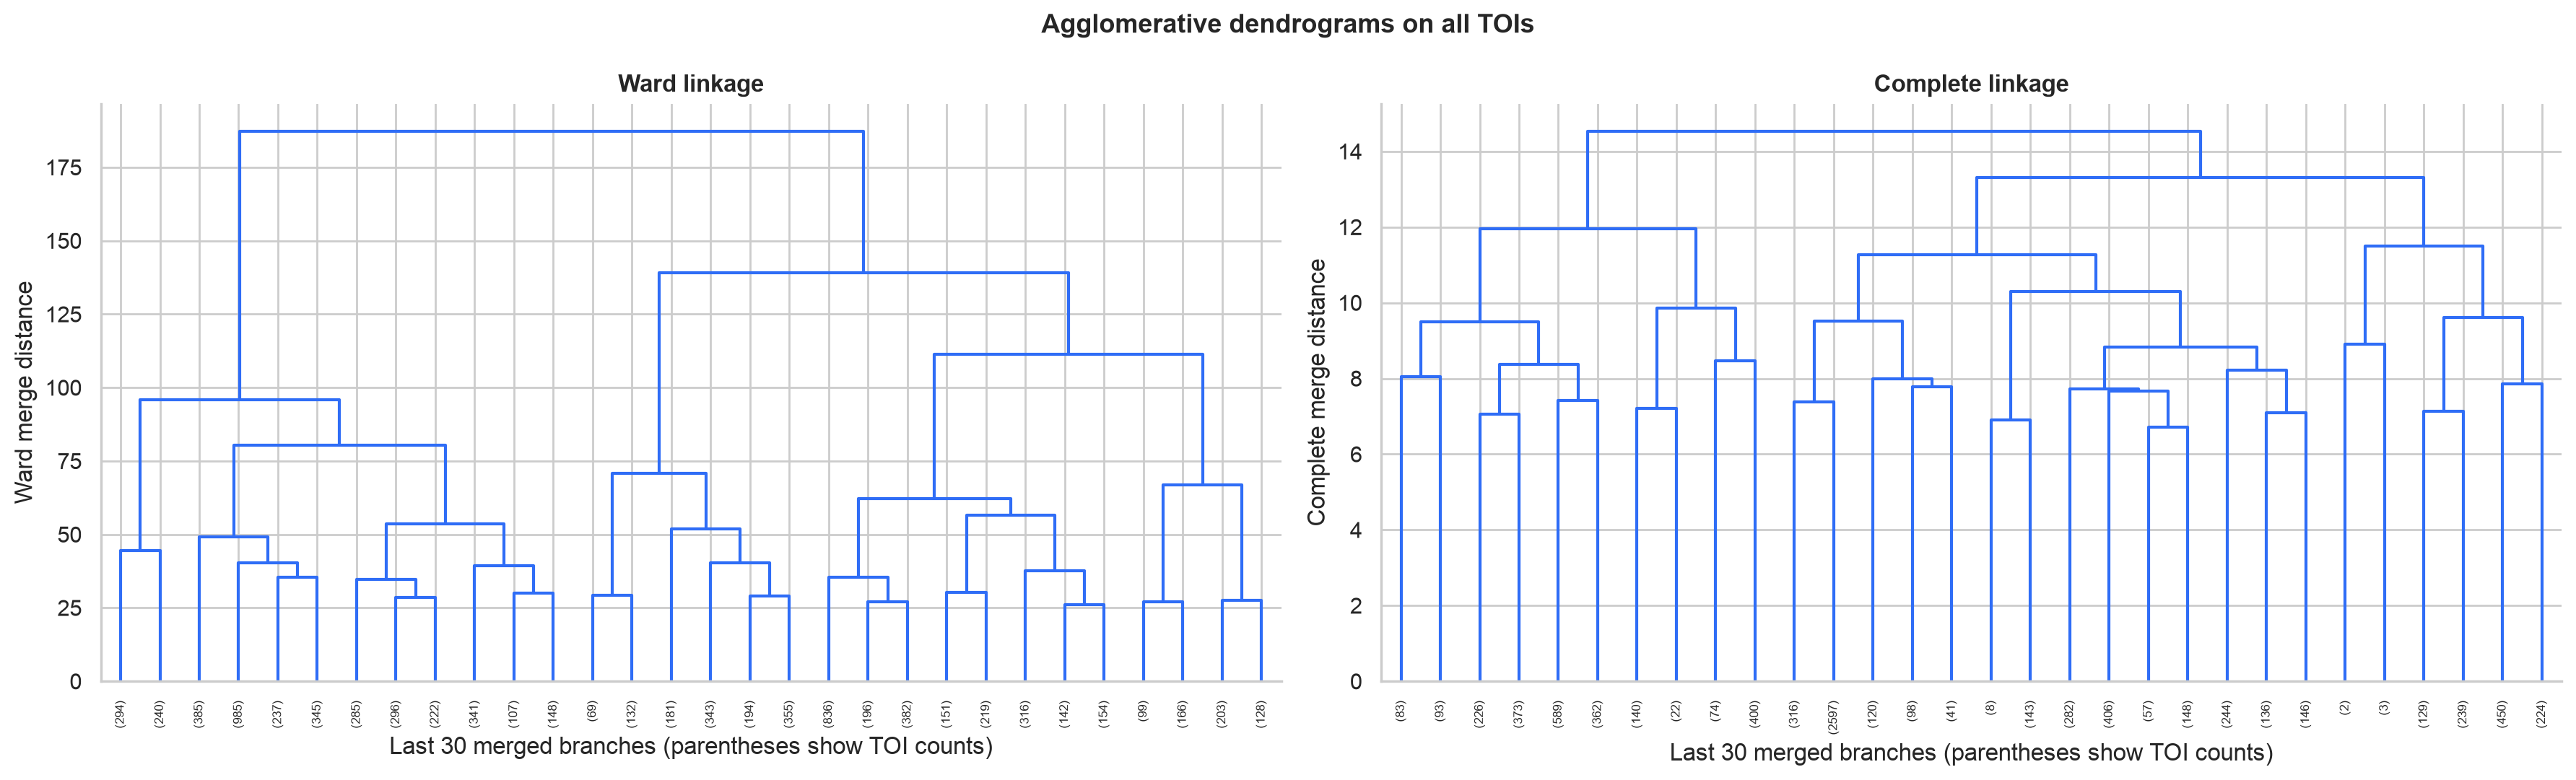

Last five Ward merge heights: [ 80.5   95.84 111.46 139.22 187.28]


In [13]:
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.manifold import TSNE

os.makedirs('figures/Agglomerative', exist_ok=True)
LINKAGES = ['ward', 'complete', 'average']
agg_trees = {method: linkage(X.to_numpy(), method=method, metric='euclidean') for method in LINKAGES}

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), dpi=200)
for ax, method in zip(axes, ['ward', 'complete']):
    dendrogram(agg_trees[method], truncate_mode='lastp', p=30, show_leaf_counts=True,
               leaf_rotation=90, leaf_font_size=6, color_threshold=0,
               above_threshold_color='#2f6df6', ax=ax)
    ax.set(xlabel='Last 30 merged branches (parentheses show TOI counts)',
           ylabel=f'{method.title()} merge distance')
    ax.set_title(f'{method.title()} linkage', fontsize=12, fontweight='bold')
    sns.despine(ax=ax)
fig.suptitle('Agglomerative dendrograms on all TOIs', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Agglomerative/dendrogram.png', dpi=300, bbox_inches='tight')
plt.show()

print('Last five Ward merge heights:', np.round(agg_trees['ward'][-5:, 2], 2))

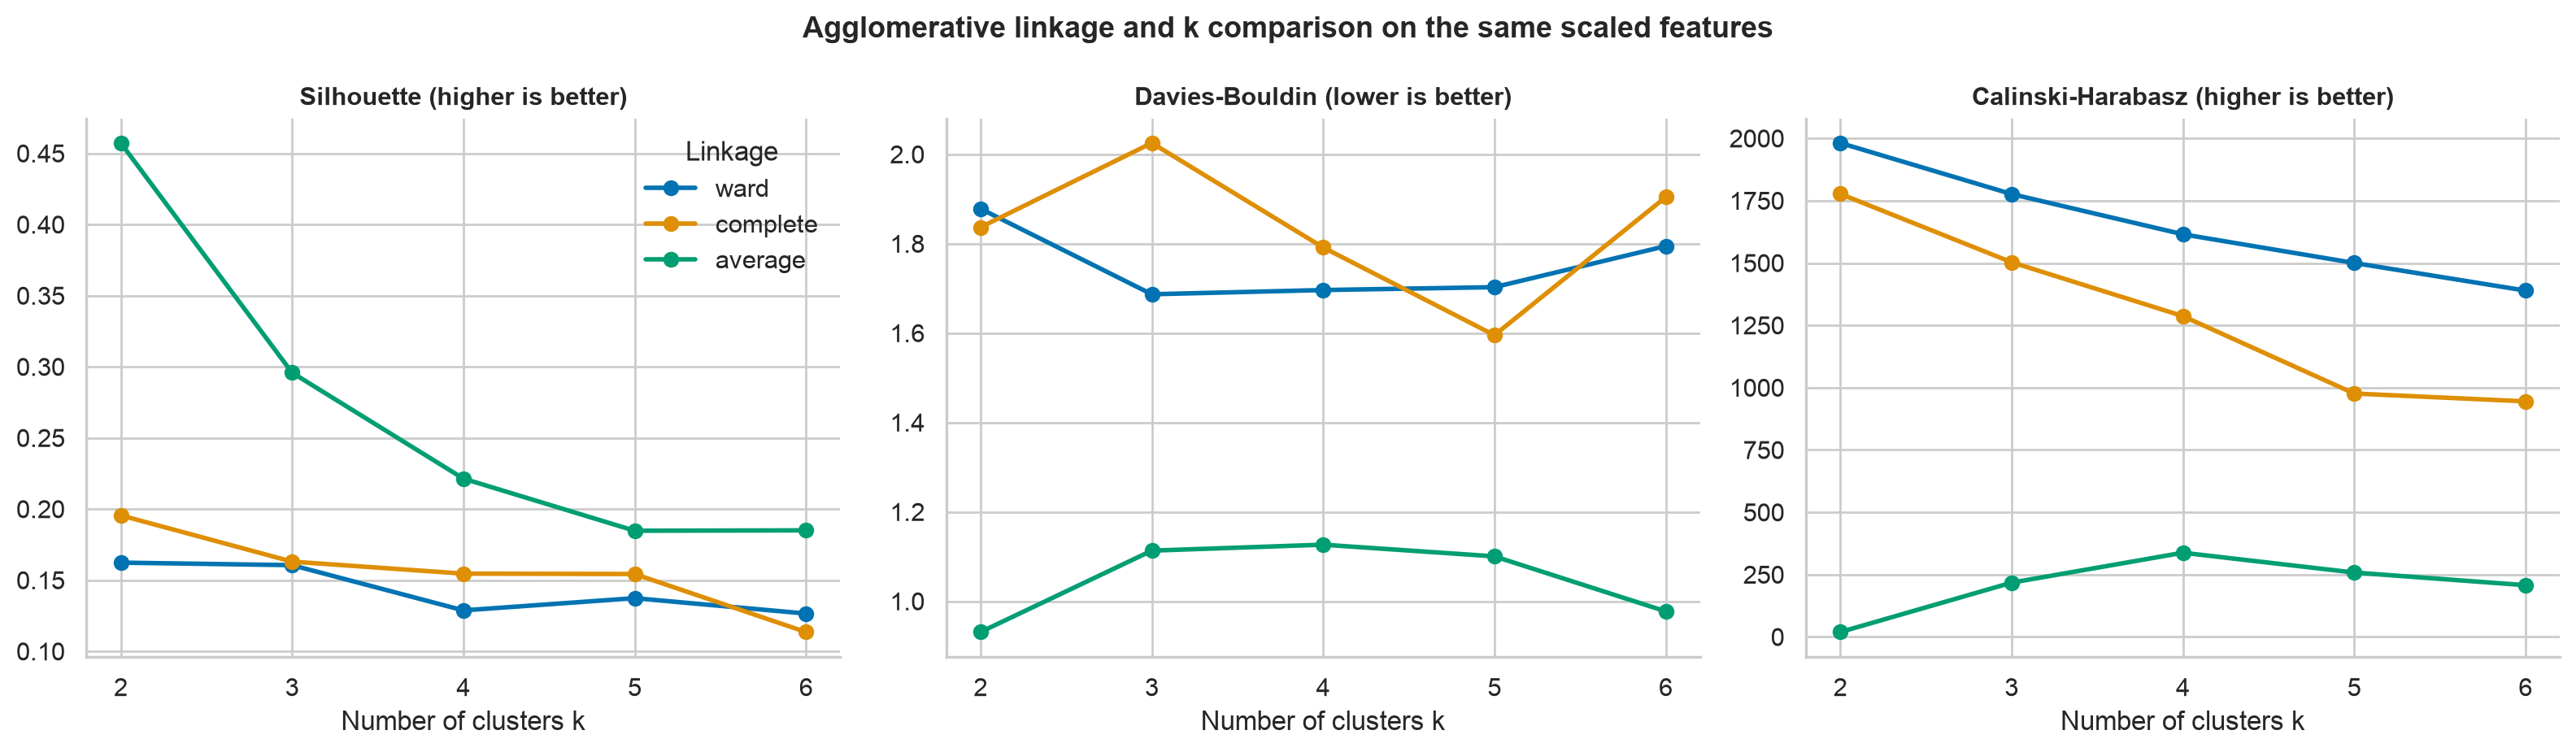

Scores and minimum cluster size for each cut:


,linkage,k,smallest cluster,smallest share (%),silhouette (sample),davies_bouldin,calinski_harabasz
0,ward,2,3885,47.6629,0.1623,1.8782,1981.5089
1,ward,3,1274,15.6300,0.1606,1.6869,1776.7549
2,ward,4,596,7.3120,0.1288,1.6963,1615.2704
3,ward,5,534,6.5513,0.1374,1.7027,1500.2028
4,ward,6,534,6.5513,0.1266,1.7946,1389.4251
5,complete,2,2362,28.9780,0.1956,1.8368,1777.4207
6,complete,3,1047,12.8450,0.1631,2.0253,1503.1441
7,complete,4,636,7.8027,0.1546,1.7916,1287.0173
8,complete,5,5,0.0613,0.1544,1.5953,976.4460
9,complete,6,5,0.0613,0.1136,1.9042,945.0513


Candidates with every cluster holding at least 5% of TOIs, sorted by silhouette:


,linkage,k,smallest cluster,smallest share (%),silhouette (sample),davies_bouldin,calinski_harabasz
5,complete,2,2362,28.9780,0.1956,1.8368,1777.4207
6,complete,3,1047,12.8450,0.1631,2.0253,1503.1441
0,ward,2,3885,47.6629,0.1623,1.8782,1981.5089
1,ward,3,1274,15.6300,0.1606,1.6869,1776.7549
7,complete,4,636,7.8027,0.1546,1.7916,1287.0173
3,ward,5,534,6.5513,0.1374,1.7027,1500.2028
2,ward,4,596,7.3120,0.1288,1.6963,1615.2704
4,ward,6,534,6.5513,0.1266,1.7946,1389.4251


In [14]:
# Build each hierarchy once; cut the same full-data tree at several values of k.
# Include every small cluster in the silhouette sample so it cannot disappear by chance.
rng = np.random.default_rng(RANDOM_STATE)
base_sample_idx = rng.choice(len(X), size=min(2000, len(X)), replace=False)
agg_sweep_rows = []
for method, tree in agg_trees.items():
    for k in range(2, 7):
        lab = cut_tree(tree, n_clusters=k).ravel()
        sizes = np.bincount(lab)
        sample_idx = np.unique(np.r_[base_sample_idx, [np.flatnonzero(lab == c)[0] for c in range(k)]])
        sample_lab = lab[sample_idx]
        agg_sweep_rows.append({
            'linkage': method, 'k': k, 'smallest cluster': int(sizes.min()),
            'smallest share (%)': 100 * sizes.min() / len(X),
            'silhouette (sample)': silhouette_score(X.iloc[sample_idx], sample_lab),
            'davies_bouldin': davies_bouldin_score(X, lab),
            'calinski_harabasz': calinski_harabasz_score(X, lab),
        })
agg_sweep = pd.DataFrame(agg_sweep_rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.7), dpi=200)
for ax, (metric, title) in zip(axes, [
    ('silhouette (sample)', 'Silhouette (higher is better)'),
    ('davies_bouldin', 'Davies-Bouldin (lower is better)'),
    ('calinski_harabasz', 'Calinski-Harabasz (higher is better)')]):
    for method in LINKAGES:
        part = agg_sweep[agg_sweep['linkage'] == method]
        ax.plot(part['k'], part[metric], marker='o', lw=2, label=method)
    ax.set(xlabel='Number of clusters k', xticks=range(2, 7))
    ax.set_title(title, fontsize=11, fontweight='bold')
    sns.despine(ax=ax)
axes[0].legend(title='Linkage', frameon=False)
fig.suptitle('Agglomerative linkage and k comparison on the same scaled features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Agglomerative/linkage_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print('Scores and minimum cluster size for each cut:')
display(agg_sweep.round(4))
print('Candidates with every cluster holding at least 5% of TOIs, sorted by silhouette:')
display(agg_sweep.loc[agg_sweep['smallest share (%)'] >= 5]
        .sort_values('silhouette (sample)', ascending=False).round(4))

**Observation (D2):** The Ward and complete dendrograms show different merge orders; neither has a single gap that fixes the best cut on its own. With the same scaled input, complete linkage at `k = 2` gives the highest sampled silhouette among cuts in which every group contains at least 5% of the TOIs. Ward at `k = 2` yields more even groups and a higher Calinski-Harabasz score, but a lower silhouette. Average linkage at `k = 2` leaves only five TOIs in its smaller group, so its low Davies-Bouldin score describes outlier isolation rather than a useful two-group partition. We select **complete linkage, k = 2** using the size guard and silhouette, and report the full-data scores below. The metrics express different notions of a good partition; none uses the disposition labels.

### D3. Final model and PCA view

Fit complete linkage at the selected `k`. Cluster IDs are arbitrary. The PCA coordinates from Section C are reused **only for display**; the hierarchy was built in all 11 scaled dimensions.

Agglomerative: complete linkage, k = 2
Cluster sizes: {0: 5789, 1: 2362}


,Algorithm,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Agglomerative,2,0.1943,1.8368,1777.4207


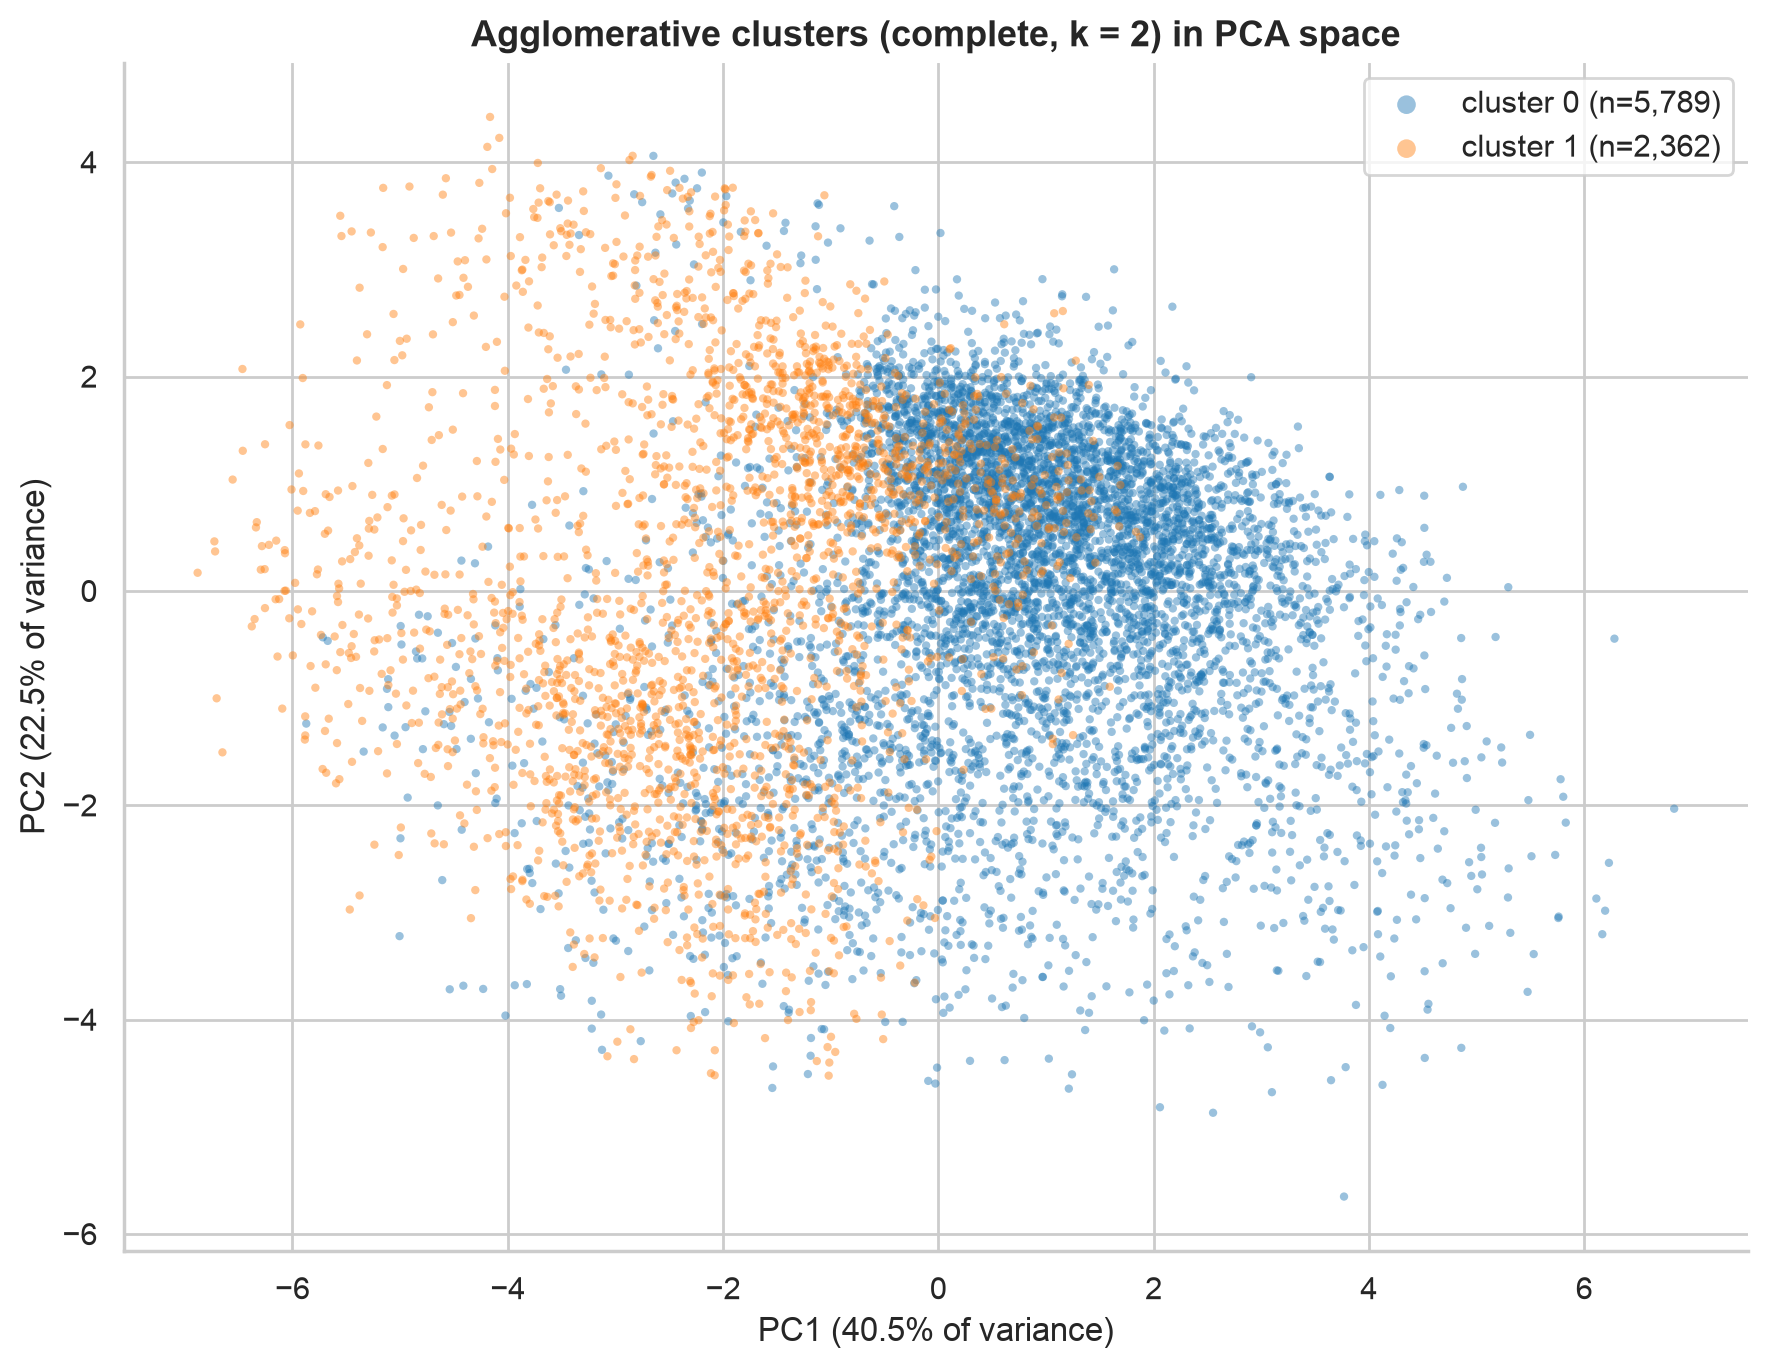

In [15]:
AGG_LINKAGE = 'complete'
AGG_K = 2
agg_model = AgglomerativeClustering(n_clusters=AGG_K, linkage=AGG_LINKAGE, metric='euclidean')
agg_labels = pd.Series(agg_model.fit_predict(X), index=X.index, name='agglomerative_cluster')
print(f'Agglomerative: {AGG_LINKAGE} linkage, k = {AGG_K}')
print('Cluster sizes:', agg_labels.value_counts().sort_index().to_dict())
agg_scores = score_clustering('Agglomerative', agg_labels)
display(pd.DataFrame([agg_scores]).round(4))

fig, ax = plt.subplots(figsize=(9, 7), dpi=200)
for c, color in enumerate(sns.color_palette('tab10', AGG_K)):
    mask = agg_labels == c
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=9, alpha=0.45, color=color,
               edgecolor='none', label=f'cluster {c} (n={mask.sum():,})')
ax.set(xlabel=f'PC1 ({ev[0]:.1f}% of variance)', ylabel=f'PC2 ({ev[1]:.1f}% of variance)')
ax.set_title(f'Agglomerative clusters ({AGG_LINKAGE}, k = {AGG_K}) in PCA space', fontsize=13, fontweight='bold')
leg = ax.legend(frameon=True)
for handle in leg.legend_handles:
    handle.set_sizes([45])
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('figures/Agglomerative/pca_clusters.png', dpi=300, bbox_inches='tight')
plt.show()

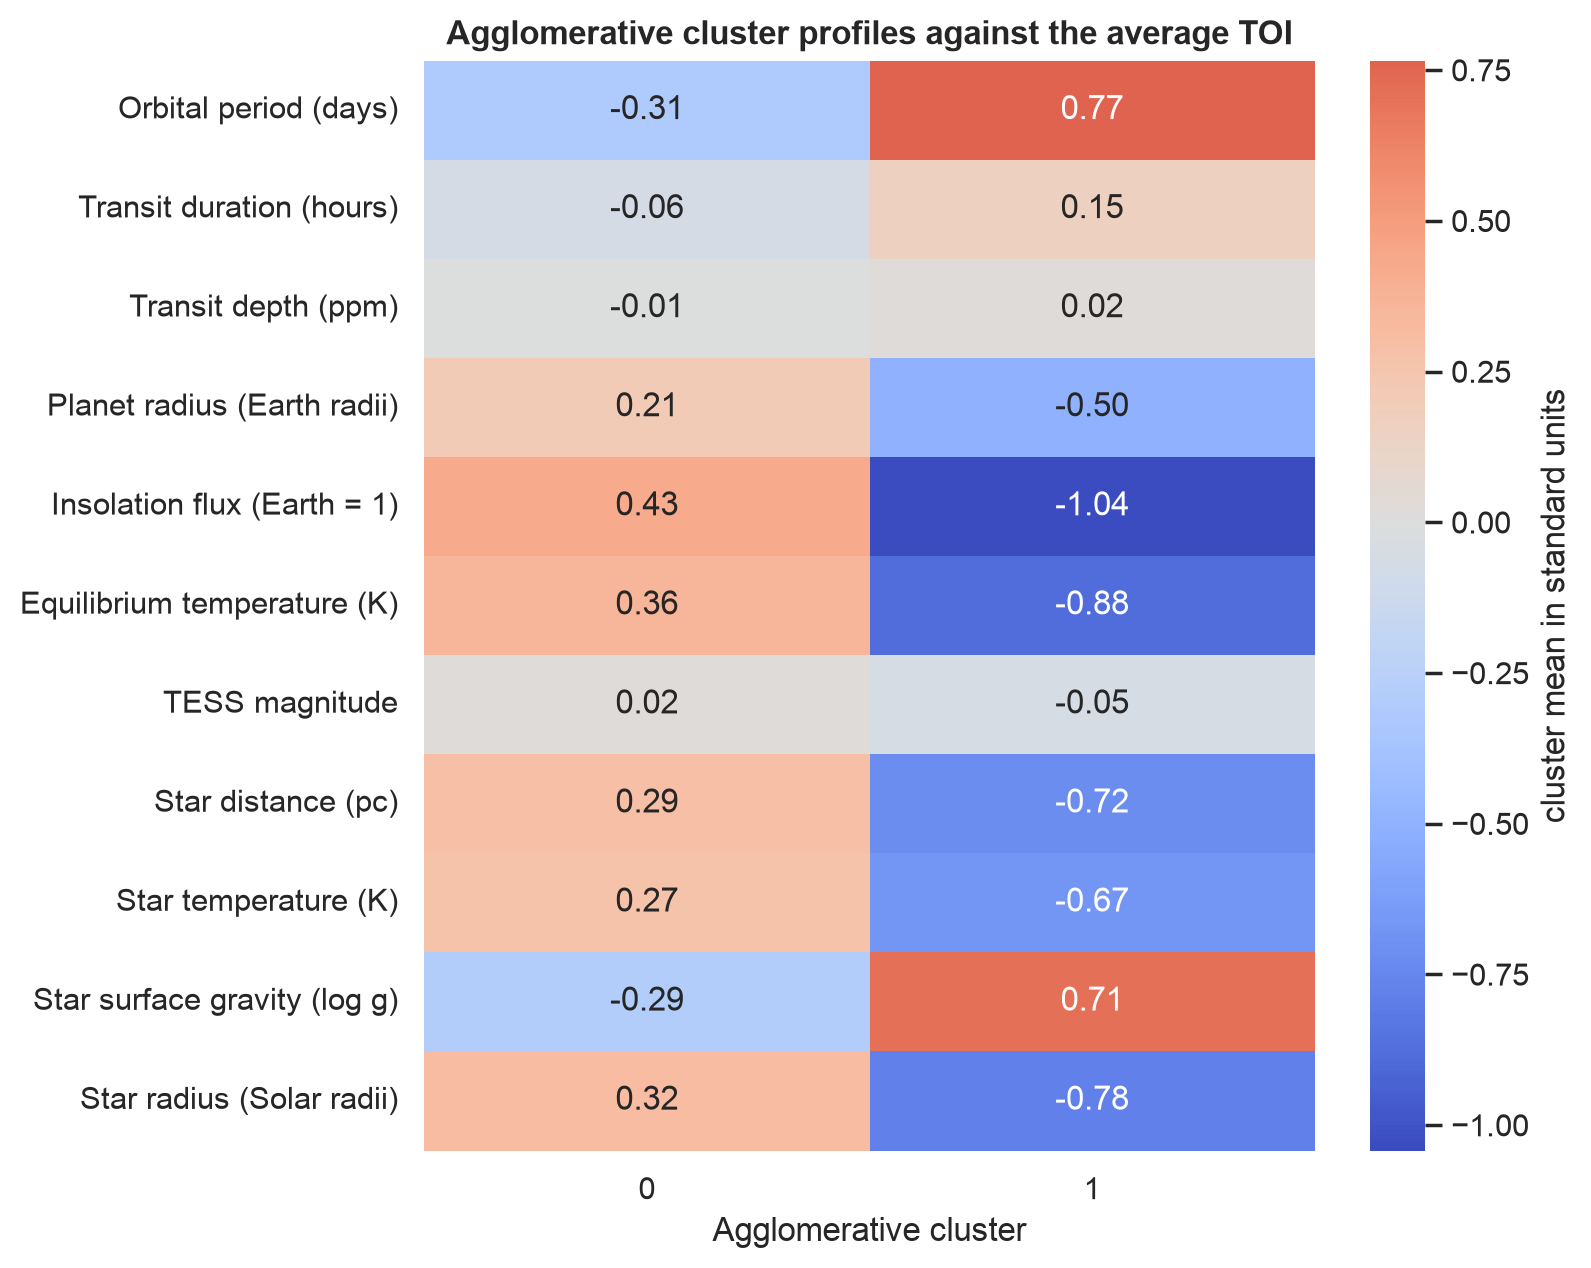

,cluster 0,cluster 1,overall median
Orbital period (days),3.42,10.06,4.15
Transit duration (hours),2.68,3.00,2.75
Transit depth (ppm),4880.25,4318.23,4742.00
Planet radius (Earth radii),11.83,6.24,10.49
Insolation flux (Earth = 1),746.73,45.34,378.49
Equilibrium temperature (K),1420.00,689.38,1194.99
TESS magnitude,11.96,11.69,11.88
Star distance (pc),488.17,167.22,370.69
Star temperature (K),5983.96,5177.90,5799.35
Star surface gravity (log g),4.24,4.52,4.33


In [16]:
# Median feature values in original units, plus standardized means on a common heatmap scale.
agg_profile = X_raw.assign(cluster=agg_labels).groupby('cluster').median().T
agg_profile.index = [FEATURES[c] for c in agg_profile.index]
agg_profile.columns = [f'cluster {c}' for c in agg_profile.columns]
agg_profile['overall median'] = X_raw.median().values

agg_zmeans = X.assign(cluster=agg_labels).groupby('cluster').mean().T
agg_zmeans.index = [FEATURES[c] for c in agg_zmeans.index]
fig, ax = plt.subplots(figsize=(8, 6.5), dpi=200)
sns.heatmap(agg_zmeans, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            cbar_kws={'label': 'cluster mean in standard units'}, ax=ax)
ax.set(xlabel='Agglomerative cluster')
ax.set_title('Agglomerative cluster profiles against the average TOI', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Agglomerative/cluster_profiles.png', dpi=300, bbox_inches='tight')
plt.show()
display(agg_profile.round(2))

### D4. Results and interpretation

The TFOPWG disposition is joined back only here, after the clustering is fixed. Counts and within-cluster percentages let us describe each group without treating disposition as a training target.

Rows per cluster and disposition group:


tfopwg_disp,candidate,not a planet,planet,unknown
agglomerative_cluster,,,,
0,3808,1171,808,2
1,1502,244,613,3


Share of each cluster (%):


tfopwg_disp,candidate,not a planet,planet,unknown
agglomerative_cluster,,,,
0,65.8,20.2,14.0,0.0
1,63.6,10.3,26.0,0.1


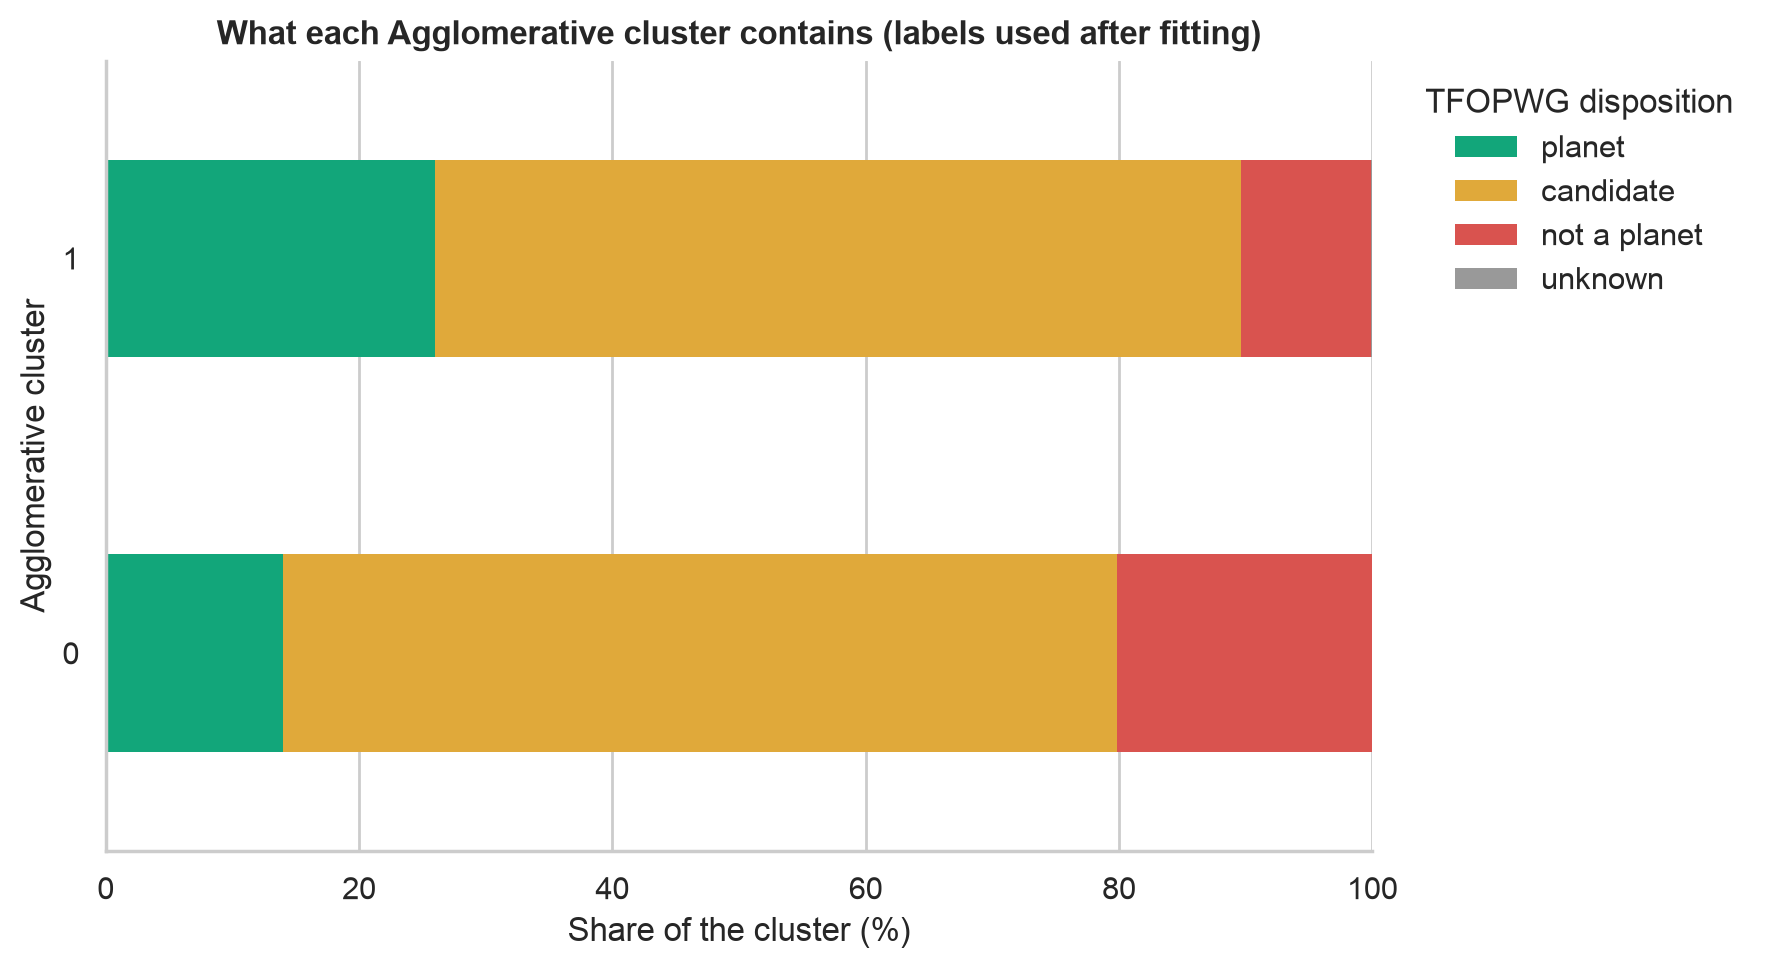

Fine-grained TFOPWG disposition counts:


tfopwg_disp,APC,CP,FA,FP,KP,PC,missing
agglomerative_cluster,,,,,,,
0,396,356,60,1111,452,3412,2
1,94,459,40,204,154,1408,3


In [17]:
agg_counts = pd.crosstab(agg_labels, disp_group)
agg_share = (pd.crosstab(agg_labels, disp_group, normalize='index') * 100).round(1)
print('Rows per cluster and disposition group:')
display(agg_counts)
print('Share of each cluster (%):')
display(agg_share)

fig, ax = plt.subplots(figsize=(9, 5), dpi=200)
agg_colors = {'planet': '#12a67a', 'candidate': '#e0a93a', 'not a planet': '#d9534f', 'unknown': '#999999'}
agg_share[order].plot(kind='barh', stacked=True, ax=ax,
                      color=[agg_colors[c] for c in order], edgecolor='none')
ax.set(xlabel='Share of the cluster (%)', ylabel='Agglomerative cluster')
ax.set_title('What each Agglomerative cluster contains (labels used after fitting)', fontsize=12, fontweight='bold')
ax.legend(title='TFOPWG disposition', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('figures/Agglomerative/clusters_vs_disposition.png', dpi=300, bbox_inches='tight')
plt.show()
print('Fine-grained TFOPWG disposition counts:')
display(pd.crosstab(agg_labels, labels.fillna('missing')))

### D5. t-SNE view

t-SNE maps nearby rows in the 11-feature scaled space onto two dimensions. We use a fixed random sample of 2,500 TOIs so the figure remains legible and runtime stays manageable. Its axes and distances between distant islands do **not** have physical units; use it to inspect local mixing, not to score the clustering. The model labels are inherited from the full-data fit.

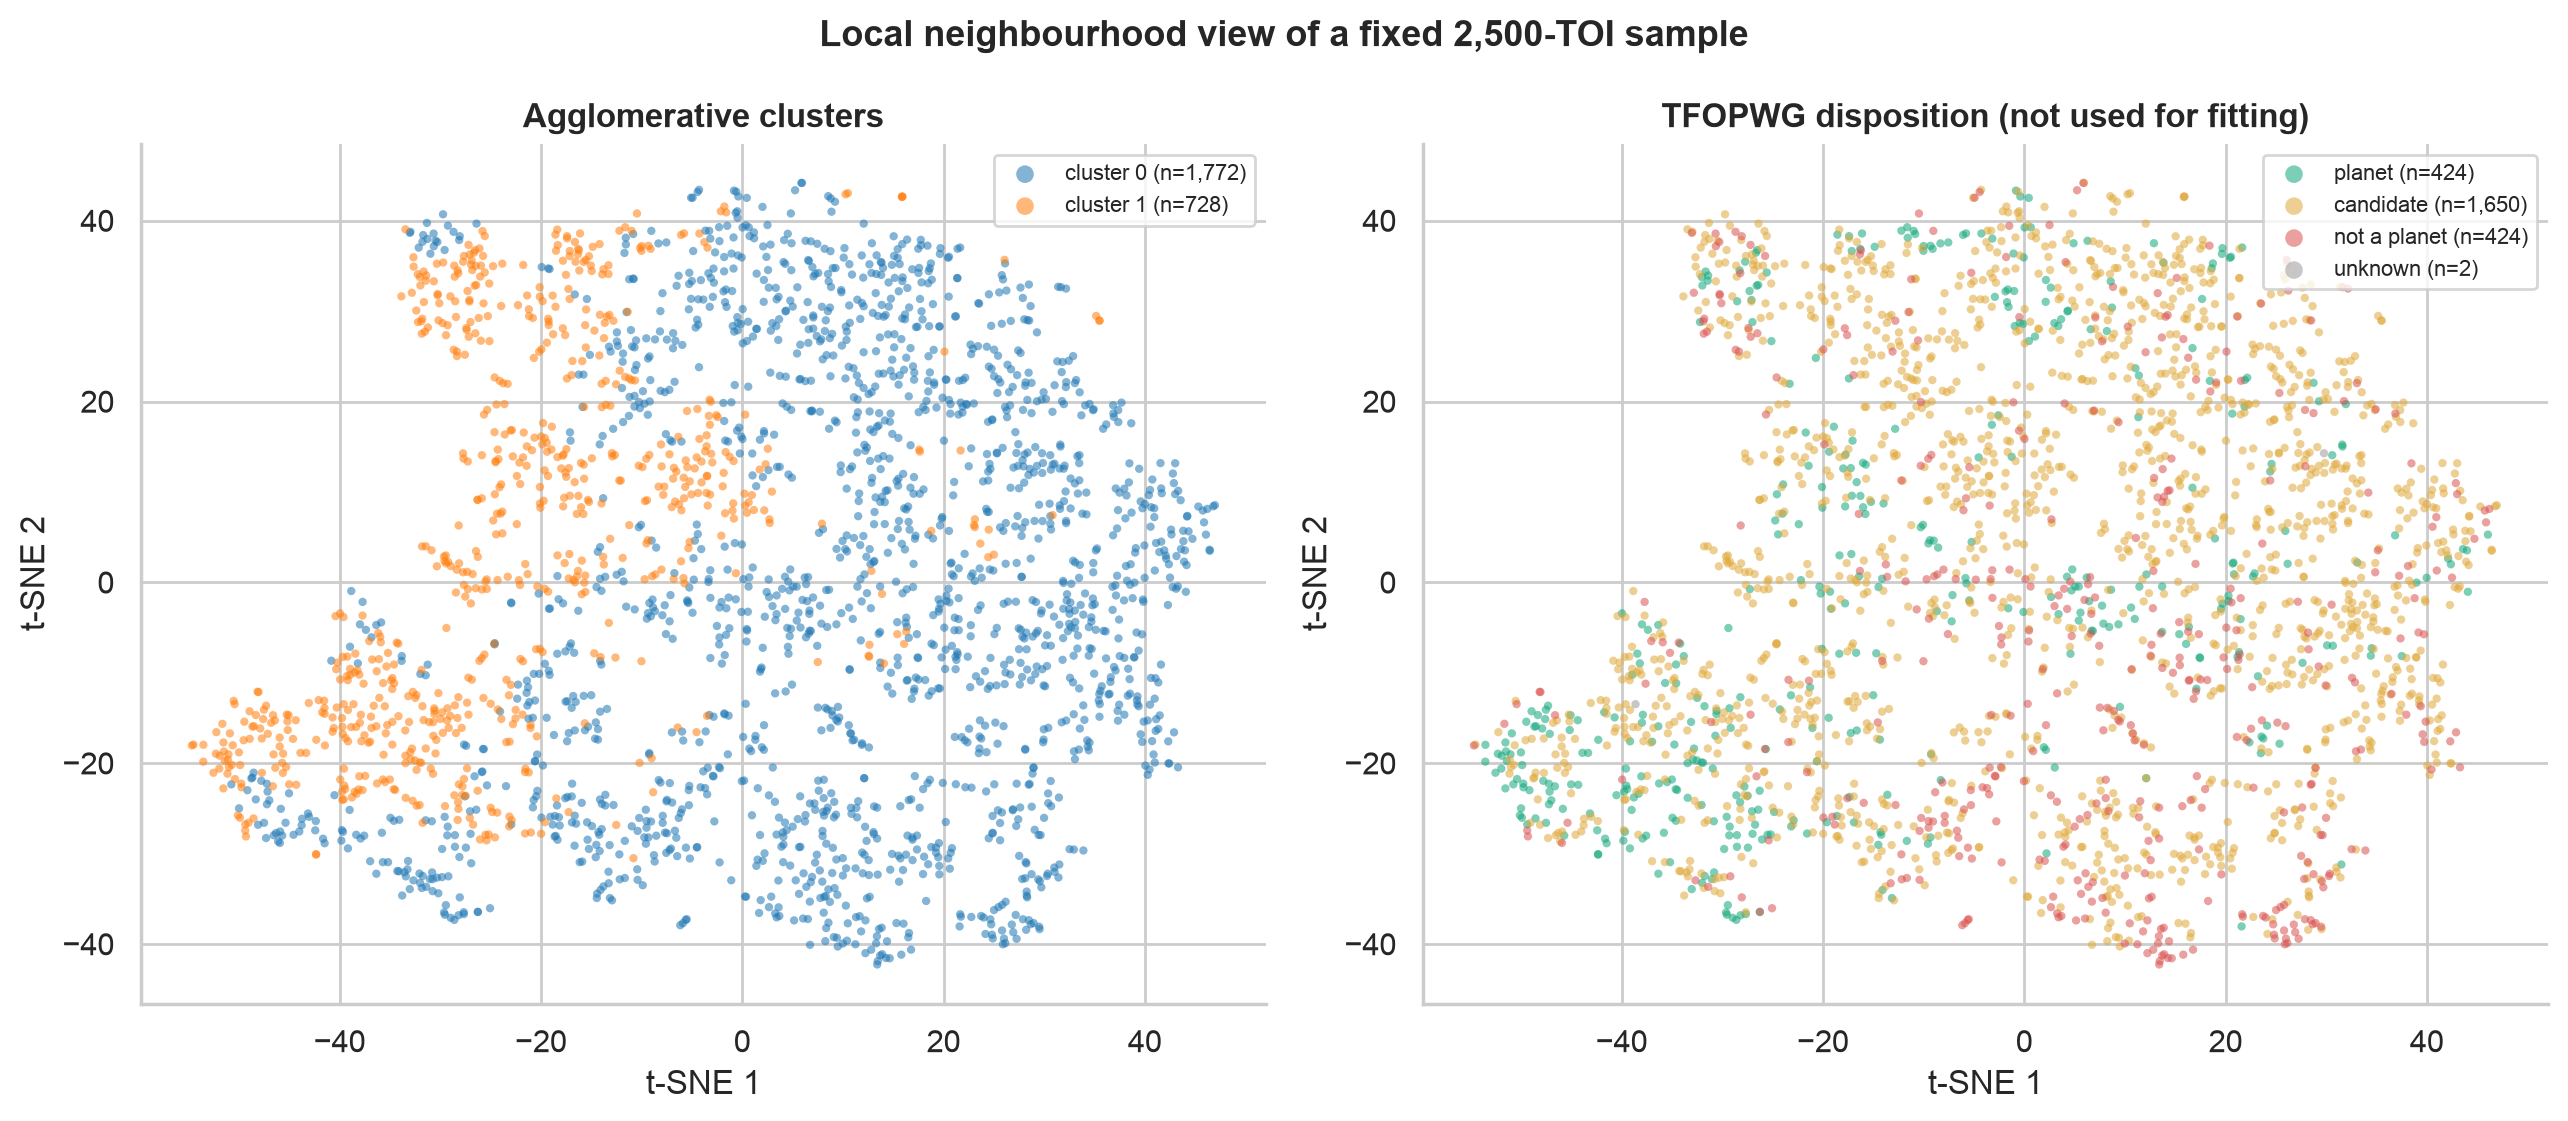

In [18]:
tsne_idx = np.random.default_rng(RANDOM_STATE).choice(len(X), size=min(2500, len(X)), replace=False)
X_tsne = TSNE(n_components=2, perplexity=35, learning_rate='auto', init='pca',
              max_iter=1000, random_state=RANDOM_STATE).fit_transform(X.iloc[tsne_idx])
fig, axes = plt.subplots(1, 2, figsize=(13, 5.7), dpi=200)
for c, color in enumerate(sns.color_palette('tab10', AGG_K)):
    mask = agg_labels.iloc[tsne_idx].to_numpy() == c
    axes[0].scatter(X_tsne[mask, 0], X_tsne[mask, 1], s=9, alpha=0.55, color=color,
                    edgecolor='none', label=f'cluster {c} (n={mask.sum():,})')
for group in order:
    mask = disp_group.iloc[tsne_idx].to_numpy() == group
    axes[1].scatter(X_tsne[mask, 0], X_tsne[mask, 1], s=9, alpha=0.55,
                    color={'planet': '#12a67a', 'candidate': '#e0a93a', 'not a planet': '#d9534f', 'unknown': '#999999'}[group],
                    edgecolor='none', label=f'{group} (n={mask.sum():,})')
for ax, title in zip(axes, ['Agglomerative clusters', 'TFOPWG disposition (not used for fitting)']):
    ax.set(xlabel='t-SNE 1', ylabel='t-SNE 2')
    ax.set_title(title, fontsize=12, fontweight='bold')
    leg = ax.legend(fontsize=8, frameon=True)
    for handle in leg.legend_handles:
        handle.set_sizes([40])
    sns.despine(ax=ax)
fig.suptitle('Local neighbourhood view of a fixed 2,500-TOI sample', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Agglomerative/tsne_clusters.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation (D3–D5):** **Cluster 0 (5,789 TOIs, 71%)** has larger inferred planets (median 11.83 Earth radii), shorter periods (3.42 days), higher insolation (747 times Earth’s), hotter equilibrium temperatures (1,420 K) and more distant, larger host stars (488 pc; 1.45 solar radii). **Cluster 1 (2,362 TOIs, 29%)** is cooler and nearer: 6.24 Earth radii, 10.06 days, insolation 45, temperature 689 K, 167 pc and 0.85 solar radii. Transit depth is similar across groups, so the split reflects a combination of features rather than a depth threshold.

Dispositions were checked only after fitting. Cluster 1 has 26.0% confirmed or known planets and 10.3% false positives or alarms; cluster 0 has 14.0% and 20.2%, respectively. Candidates remain the majority in both (63.6% and 65.8%). The PCA view places the cooler, nearer group mostly to the left, with substantial overlap. The t-SNE sample shows local neighbourhoods, but its axes and island separations cannot be interpreted as physical distances or used to validate the score. Cluster sizes and scores above use all 8,151 rows.

## Section E - Metrics Comparison

The three required internal metrics for every algorithm registered above. Silhouette and Calinski-Harabasz are higher-is-better, Davies-Bouldin is lower-is-better.

,Algorithm,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,2,0.2752,1.5024,2969.0180
1,Agglomerative,2,0.1943,1.8368,1777.4207


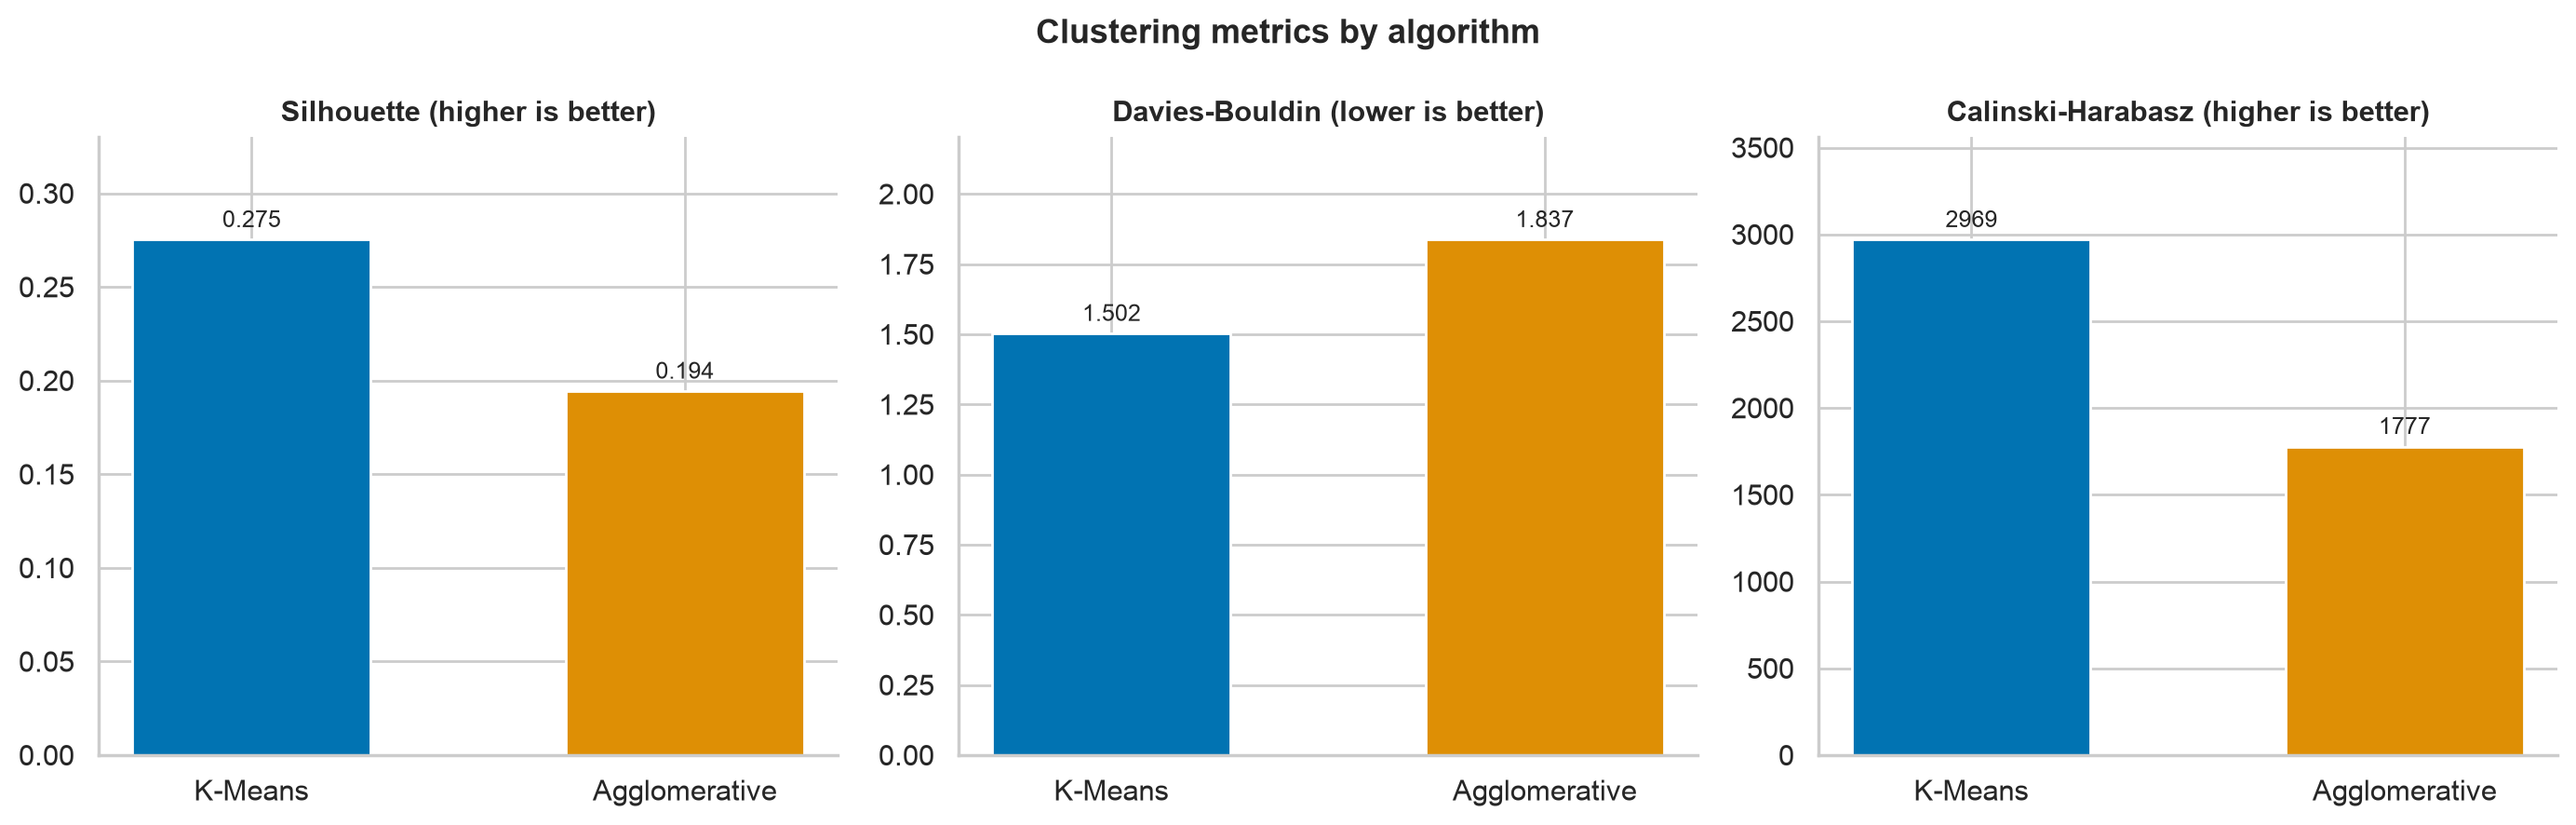

In [19]:
results_df = pd.DataFrame(cluster_results).sort_values('Silhouette', ascending=False).reset_index(drop=True)
display(results_df.round(4))

os.makedirs('figures/Comparison', exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), dpi=200)
for ax, (metric, better) in zip(axes, [('Silhouette', 'higher is better'), ('Davies-Bouldin', 'lower is better'), ('Calinski-Harabasz', 'higher is better')]):
    bars = ax.bar(results_df['Algorithm'], results_df[metric], color=sns.color_palette('colorblind', len(results_df)), width=0.55)
    ax.bar_label(bars, fmt='%.3f' if metric != 'Calinski-Harabasz' else '%.0f', padding=3, fontsize=9)
    ax.set_title(f'{metric} ({better})', fontsize=11, fontweight='bold')
    ax.set_ylim(0, results_df[metric].max() * 1.2)
    sns.despine(ax=ax)
fig.suptitle('Clustering metrics by algorithm', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Comparison/clustering_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation (E):** On the same 8,151 scaled TOIs and with two clusters each, K-Means scores higher on silhouette (0.275 vs 0.194) and Calinski-Harabasz (2,969 vs 1,777), and lower on Davies-Bouldin (1.50 vs 1.84). By all three internal metrics, K-Means gives the cleaner two-group partition. The Agglomerative model still gives a useful nested grouping and a dendrogram; its membership differs because complete linkage considers the farthest cross-cluster pair at each merge.

## Section F - PCA Cluster Visualisation for Every Algorithm

The same two principal components from Section C, coloured by each algorithm's cluster labels, so the algorithms can be compared on one picture. The right-hand panel shows the dispositions on the same axes, again only as an after-the-fact check.

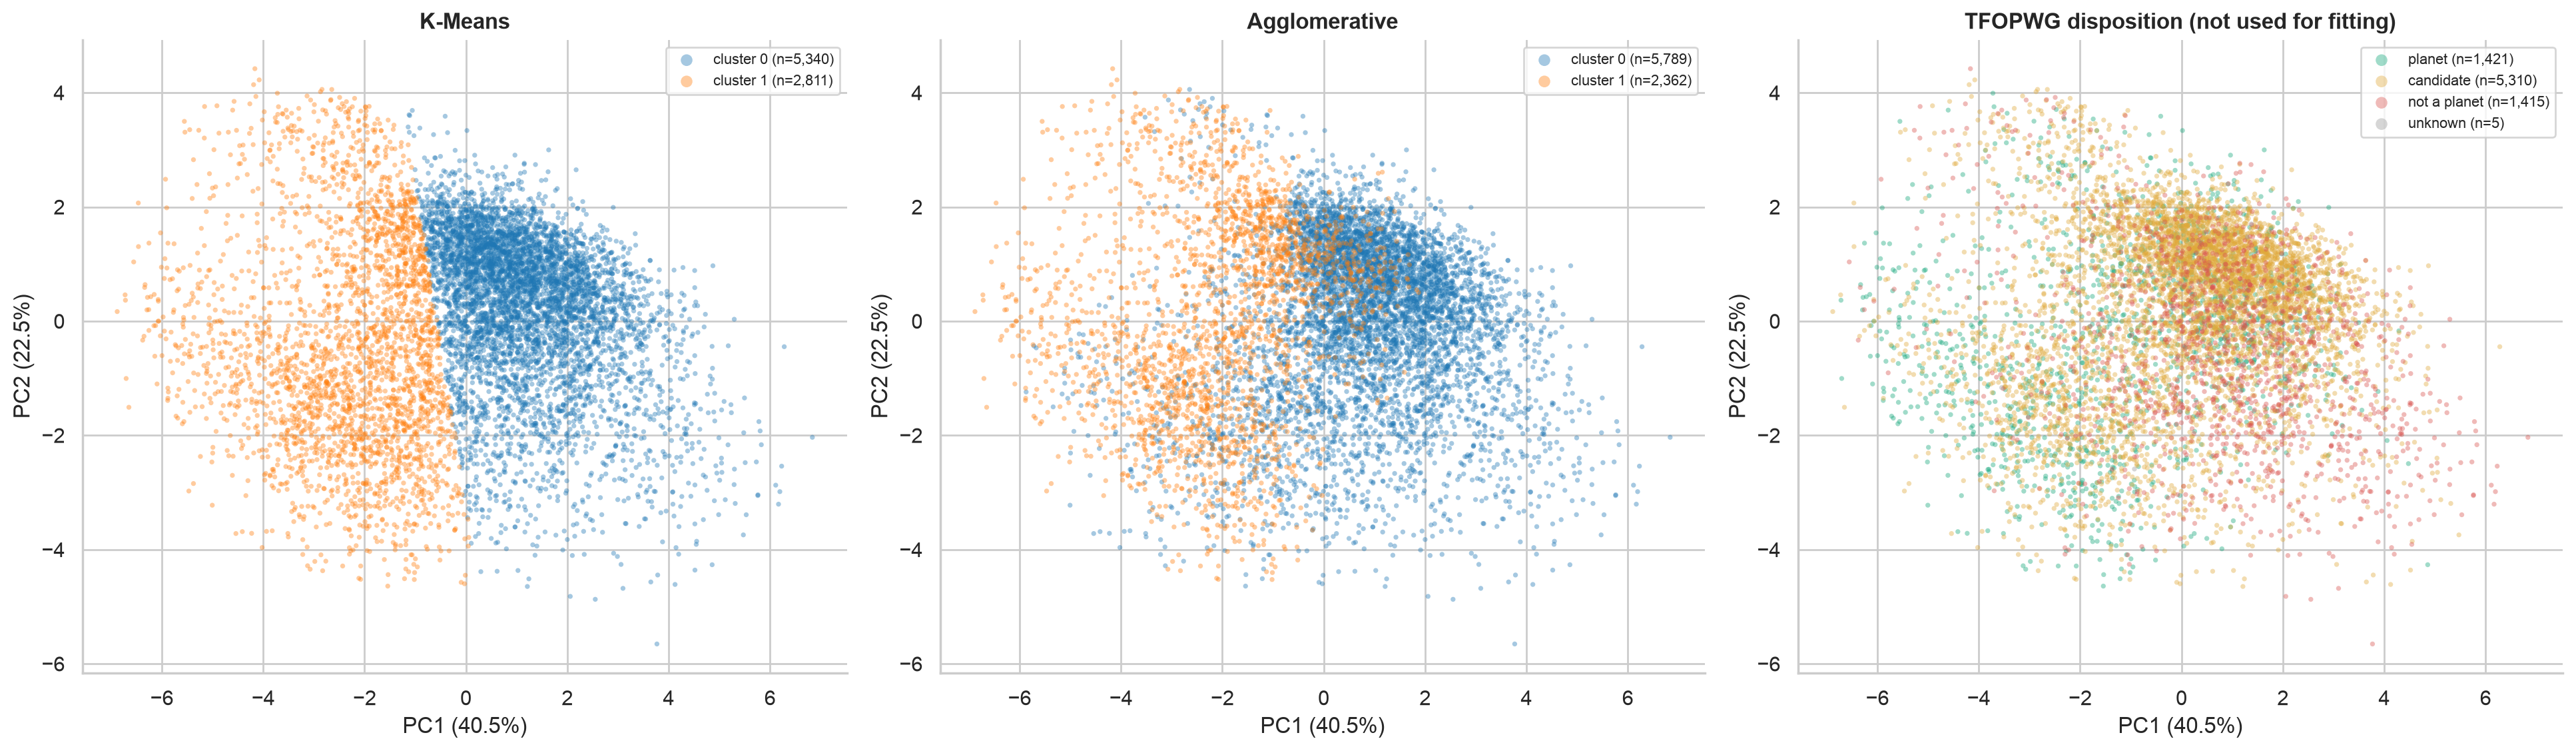

In [20]:
DISP_COLORS = {'planet': '#12a67a', 'candidate': '#e0a93a', 'not a planet': '#d9534f', 'unknown': '#999999'}
panels = list(cluster_labels.items()) + [('TFOPWG disposition (not used for fitting)', disp_group)]
fig, axes = plt.subplots(1, len(panels), figsize=(6.5 * len(panels), 5.8), dpi=200, squeeze=False)
for ax, (name, lab) in zip(axes[0], panels):
    lab = pd.Series(lab, index=X.index)
    if name in cluster_labels:
        cats = sorted(lab.unique())
        colors = sns.color_palette('tab10', len(cats))
    else:
        cats = [c for c in DISP_COLORS if c in lab.unique()]
        colors = [DISP_COLORS[c] for c in cats]
    for color, cat in zip(colors, cats):
        m = lab == cat
        label = f'cluster {cat}' if name in cluster_labels else str(cat)
        ax.scatter(X_pca[m, 0], X_pca[m, 1], s=7, alpha=0.4, color=color, edgecolor='none', label=f'{label} (n={m.sum():,})')
    ax.set_xlabel(f'PC1 ({ev[0]:.1f}%)')
    ax.set_ylabel(f'PC2 ({ev[1]:.1f}%)')
    ax.set_title(name, fontsize=12, fontweight='bold')
    leg = ax.legend(fontsize=8, frameon=True)
    for handle in leg.legend_handles:
        handle.set_sizes([40])
    sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('figures/Comparison/pca_all_algorithms.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation (F):** Both algorithms broadly separate smaller, cooler, nearer systems on the left of PC1 from larger, hotter, more distant systems on the right. K-Means makes a relatively straight split, while complete-linkage Agglomerative clustering has a more irregular boundary and more overlap in this two-dimensional projection. PC1 and PC2 explain 40.5% and 22.5% of the scaled-feature variance, so the panels omit 37.0% of the information used in fitting. The disposition panel shows confirmed and known planets concentrated toward the cooler side, while candidates and false positives remain spread across the plane. Dispositions were never used to make either set of clusters.